# EasyVisa Project

Context:

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

Objective:

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired your firm EasyVisa for data-driven solutions. You as a data scientist have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be **certified or denied** based on the drivers that significantly influence the case status.


Data Description

The data contains the different attributes of the employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* **case_status**:  Flag indicating if the Visa was certified or denied. This is the target varible.  All things revolve on classifing based on this varible.

## Libraries

In [1]:
#C1
# Mount Drive Short
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive', force_remount=True)
%cd "./drive/MyDrive/Colab Notebooks/"

!ls *.ipynb

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks
'Copy of EasyVisa_ScottHorning_Portfolio.ipynb'  'WSJ Cherry Picking 001.ipynb'
 EasyVisa_ScottHorning_Portfolio.ipynb


In [2]:
 #C2
 # House keeping... print the table of contents
import json


NB = Path("EasyVisa_ScottHorning_Portfolio.ipynb")

nb = json.loads(NB.read_text())

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "markdown":
        continue
    src = "".join(cell.get("source") or []).strip()
    if not src:
        continue
    first = src.splitlines()[0].rstrip()
    hashes = 0
    for ch in first:
        if ch == "#":
            hashes = hashes + 1
        else:
            break
    level = hashes if hashes > 0 else 0
    indent = "  " * max(level - 1, 0)
    print(f"{i:03d}  {indent}{first[:100]}")

000  # EasyVisa Project
001    ## Libraries
006    ##Importing Data
008  #User Defined Functions
009    ##Treat Outliers
011    ##model_performance_classification_sklearn
013    ##confusion_matrix_sklearn
015    ##crosstab_frequency_table
017    ## value_counts_perc
019    ##stacked_barplot(data, predictor, target)
021    ##category_boxplot(df_tmp, cat, num, hhue="empty", wider=0, taller=0)
023    ##labeled_barplot(data, feature, perc=False, n=None)
025    ##histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None)
027    ##Grouped Labeled Barplot
029    ##Glimpse
031  # Data Overview (Observations and Sanity checks)
032    ##Head, tail and shape
039    ## Statistical summary
040    ## Exploratory Data Analysis (EDA)
041      ###Univariate Analysis
042        ####continent
044        ####education_of_employee
046        ####has_job_experience
048        ####requires_job_training
050        ####no_of_employees
053        ####yr_of_estab
055        ####region_of_employment

In [3]:
#C3
import warnings
warnings.filterwarnings("ignore")

# libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)

# Library to transform data
from scipy import stats

# libraries different ensemble classifiers
from sklearn.ensemble import     BaggingClassifier
from sklearn.ensemble import     RandomForestClassifier
from sklearn.ensemble import     AdaBoostClassifier
from sklearn.ensemble import     GradientBoostingClassifier
from sklearn.ensemble import     StackingClassifier
from sklearn.tree     import     DecisionTreeClassifier

# Library to split data
from sklearn.model_selection import train_test_split

#XGBoost
from xgboost import XGBClassifier

# libraries to get different metric scores
from sklearn         import    metrics
from sklearn         import    tree
from sklearn.metrics import    confusion_matrix
from sklearn.metrics import    accuracy_score
from sklearn.metrics import    precision_score
from sklearn.metrics import    recall_score
from sklearn.metrics import    f1_score

# To tune different models
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV


In [4]:
#C4
# format numeric data for easier readability
pd.set_option("display.float_format", lambda x: "%.2f" % x)  # to display numbers rounded off to 2 decimal places

##Importing Data

In [5]:
#C5
fn = "EasyVisa.csv"
df = pd.read_csv(fn)
df_backup = df.copy()

#User Defined Functions

I try to keep all my declares in one spot. I find it makes the code more maintainable.
The expeception would be when protyping , debugging or for the sake clarity.

##Treat Outliers


**How to find the number of bins: rule of thumb**

Freedman's rule uses the interquartile range (IQR). First calculate the bin width:

$$
binwidth = \frac{2 \times IQR}{\sqrt[3]{n}}
$$

where \(n\) is the number of rows in the dataset.

Then obtain the number of bins:

$$
bins = \frac{Range}{binwidth}
$$

This is a display choice for a histogram. It is not an outlier treatment.

**Outlier treatment**

A point is outside the whiskers when it is below the first quartile (Q1) or above the third quartile (Q3) by a chosen multiple of the IQR:

$$
lower = Q1 - 1.5 \times IQR, \quad upper = Q3 + 1.5 \times IQR
$$

Capping means clipping values to those whiskers. The multiple 1.5 is common, not required. Another multiple (0.5, 2, 3) can be used. The choice depends on the business question.

Do not cap by default. A high prevailing wage can be a real wage. A negative employee count cannot. Treat only when the value cannot be real, and say why. Otherwise leave the tails and say why not.

In [6]:
#C6
def treat_outliers(df, col):
    """
    treats outliers in a variable
    col: str, name of the numerical variable
    df: dataframe
    """
    Q1 = df[col].quantile(0.25)  # 25th quantile
    Q3 = df[col].quantile(0.75)  # 75th quantile
    IQR = Q3 - Q1                # interquartile range (IQR) (75th percentile - 25th percentile)
    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR

    # all the values smaller than lower_whisker will be assigned the value of lower_whisker
    # all the values greater than upper_whisker will be assigned the value of upper_whisker
    # the assignment will be done by using the clip function of NumPy
    df[col] = np.clip(df[col], lower_whisker, upper_whisker)

    return df



##model_performance_classification_sklearn

In [7]:
#C7
def model_performance_classification_sklearn(model, predictors, target):
# defining a function to compute different metrics to check performance of a classification model built using scikit-learn
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

##confusion_matrix_sklearn

In [8]:
#C8
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")


##crosstab_frequency_table

In [9]:
#C9
def crosstab_frequency_table(df_tmp, xCol, yCol):
    df_counts = pd.crosstab(df_tmp[xCol], df_tmp[yCol], normalize=False, margins=True)
    df_percent = pd.crosstab(df_tmp[xCol], df_tmp[yCol], normalize=True, margins=True)
    df_counts = df_counts.reset_index()
    df_percent = df_percent.reset_index()
    df_rtn = df_counts.merge(df_percent, how="inner", on=xCol, suffixes=("_count", "_percent"))
    return df_rtn

## value_counts_perc

In [10]:
#C10
def value_counts_perc(df_tmp, feature):
    df_counts = df_tmp[feature].value_counts()
    df_percntg = df_tmp[feature].value_counts(normalize=True) * 100
    df_rtn = pd.concat([df_counts, df_percntg], axis=1, keys=["count", "percentage"])
    df_rtn.loc["TOTALS", :] = list(df_rtn.sum(axis=0))
    return df_rtn

##stacked_barplot(data, predictor, target)

In [11]:
#C11
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart.

    data: dataframe
    predictor: independent variable
    target: target variable

    Bars are ordered by the least common target level, descending.
    The printed table is counts. The plot is a row percent.
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

##category_boxplot(df_tmp, cat, num, hhue="empty", wider=0, taller=0)

In [12]:
#C12
def category_boxplot(df_tmp, cat, num, hhue="empty", wider=0, taller=0):
    """
    A categorical boxplot.
    df_tmp is the dataset
    num is the numeric column
    cat is the categorical column
    hhue defaults to empty. Pass a column name to split the boxes by hue.
    wider adds inches to the default width
    taller adds inches to the default height
    """
    if hhue == "empty":
        df_tmp2 = df_tmp.groupby(cat)[num].describe().T.reset_index()
        print("\n* Comparing ", cat, " to ", num, "*\n")
        print("\n", df_tmp2, "\n")
        plt.figure(figsize=(15 + wider, 9 + taller))
        ax = sns.boxplot(data=df_tmp, x=cat, y=num)
        plt.setp(ax.get_xticklabels(), rotation=45)
        plt.show()
    else:
        df_tmp2 = df_tmp.groupby([cat, hhue])[num].describe().T.reset_index()
        print("\n* Comparing ", cat, " to ", num, " across ", hhue, "*\n")
        print("\n", df_tmp2, "\n")
        plt.figure(figsize=(15 + wider, 9 + taller))
        ax = sns.boxplot(data=df_tmp, x=cat, y=num, hue=hhue)
        plt.setp(ax.get_xticklabels(), rotation=45)
        plt.show()

##labeled_barplot(data, feature, perc=False, n=None)

In [13]:
#C13
def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

##histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None)

In [14]:
#C14
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

##Grouped Labeled Barplot


In [15]:
#C15
def grouped_labeled_barplot(data, feature, feature_2, perc=False, n=None):
    """
    Grouped barplot with a count or a percent on each bar.
    Percent is a share of the whole column, not a share within the group.
    For a certification rate, use stacked_barplot instead.

    data: dataframe
    feature: column on the x-axis
    feature_2: hue column
    perc: percentages instead of counts (default False)
    n: top n levels of feature (default None, all levels)
    """
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature_2,
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = p.get_height()

        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=9,
            xytext=(0, 5),
            textcoords="offset points",
        )

    plt.show()

# grouped_labeled_barplot(df, "education_of_employee", "full_time_position", perc=True)

##Glimpse

In [16]:
#C16
def glimpse(df):
#Glimpse
# The function glimpse takes a dataframe as a parameter and prints the shape and top, head and random rows

    print('glimpse shape...')
    print(f"{df.shape[0]} rows and {df.shape[1]} columns")
    print('glimpse head...')
    display(df.head(5))
    print('glimpse sample...')
    display(df.sample(5, replace=True))
    print('glimpse tail...')
    display(df.tail(5))


# Data Overview (Observations and Sanity checks)

##Head, tail and shape
* There are 12 columns
*There are 25,480 rows
* The column names look well formed and accurate.  
* The sample review of 15 records reveals data that appears tidy on initial.
* There are no ambigious column names



In [17]:
#C17
print('shape...')
print(f"{df.shape[0]} rows and {df.shape[1]} columns")

shape...
25480 rows and 12 columns


In [18]:
#C18
print(df.head(5).to_string())
print(df.sample(5, random_state=1).to_string())
print(df.tail(5).to_string())

#names match the dictionary, and the wage unit is mixed.

  case_id continent education_of_employee has_job_experience requires_job_training  no_of_employees  yr_of_estab region_of_employment  prevailing_wage unit_of_wage full_time_position case_status
0  EZYV01      Asia           High School                  N                     N            14513         2007                 West           592.20         Hour                  Y      Denied
1  EZYV02      Asia              Master's                  Y                     N             2412         2002            Northeast         83425.65         Year                  Y   Certified
2  EZYV03      Asia            Bachelor's                  N                     Y            44444         2008                 West        122996.86         Year                  Y      Denied
3  EZYV04      Asia            Bachelor's                  N                     N               98         1897                 West         83434.03         Year                  Y      Denied
4  EZYV05    Africa      

In [19]:
#C19
#print a concise summary of the DataFrame
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB
None


In [20]:
#C20
#checking missing values across each columns
print(df.isnull().sum())

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64


In [21]:
#C21
print(df["case_id"].duplicated().sum())

0


In [22]:
#C22
#  statistical summary of the data
print(df.describe(include='all').T)

                         count unique         top   freq     mean      std  \
case_id                  25480  25480   EZYV25480      1      NaN      NaN   
continent                25480      6        Asia  16861      NaN      NaN   
education_of_employee    25480      4  Bachelor's  10234      NaN      NaN   
has_job_experience       25480      2           Y  14802      NaN      NaN   
requires_job_training    25480      2           N  22525      NaN      NaN   
no_of_employees       25480.00    NaN         NaN    NaN  5667.04 22877.93   
yr_of_estab           25480.00    NaN         NaN    NaN  1979.41    42.37   
region_of_employment     25480      5   Northeast   7195      NaN      NaN   
prevailing_wage       25480.00    NaN         NaN    NaN 74455.81 52815.94   
unit_of_wage             25480      4        Year  22962      NaN      NaN   
full_time_position       25480      2           Y  22773      NaN      NaN   
case_status              25480      2   Certified  17018      Na

## Statistical summary

* `case_id` has 25,480 unique values. That matches the duplicate check.
* `continent` has 6 levels. Asia is 16,861 rows, about 66 percent.
* `education_of_employee` has 4 levels. Bachelor's is 10,234, about 40 percent.
* `has_job_experience`: Y is 14,802, about 58 percent.
* `requires_job_training`: N is 22,525, about 88 percent.
* `region_of_employment` has 5 levels. Northeast is 7,195, about 28 percent.
* `unit_of_wage` has 4 levels. Year is 22,962, about 90 percent.
* `full_time_position`: Y is 22,773, about 89 percent.
* `case_status`: Certified is 17,018, about 67 percent. Denied is 8,462, about 33 percent. Certified is the majority class.
* `no_of_employees` runs from -26 to 602,069. The median is 2,109 and the mean is 5,667. The minimum cannot be a real headcount. The maximum pulls the mean up. Do not take the absolute value in this cell.
* `yr_of_estab` runs from 1800 to 2016. The median is 1997. Old is not the same as wrong.
* `prevailing_wage` runs from 2.14 to 319,210. The mean, 74,456, mixes hour, week, month, and year. Do not read it as a yearly wage.


## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

###Univariate Analysis

####continent
66% of applicants are from Asia.
lest than 6% of applicants come from South america, Afria and Oceania combined.

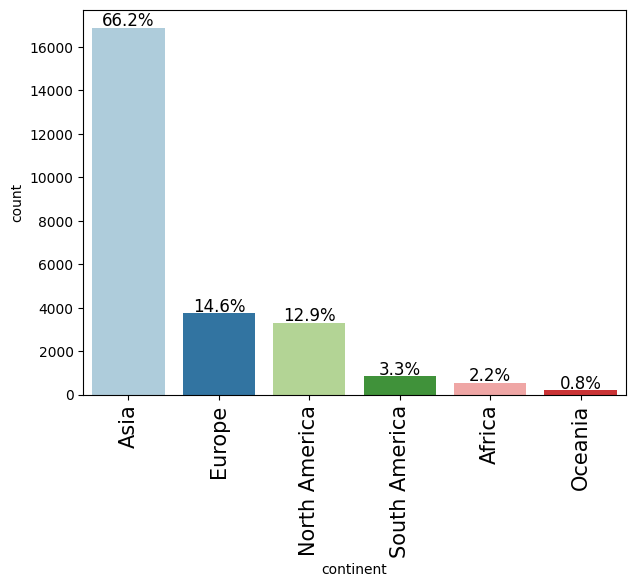

                 count  percentage
continent                         
Asia          16861.00       66.17
Europe         3732.00       14.65
North America  3292.00       12.92
South America   852.00        3.34
Africa          551.00        2.16
Oceania         192.00        0.75
TOTALS        25480.00      100.00


In [23]:
#C22
labeled_barplot(df, 'continent', perc=True)
print(value_counts_perc(df,'continent'))

####education_of_employee
~86% of applicants have Batchelor degree or better. ~ 14% are High School only.


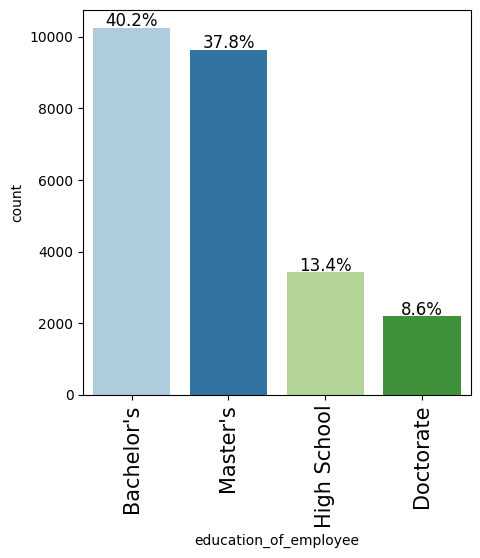

                         count  percentage
education_of_employee                     
Bachelor's            10234.00       40.16
Master's               9634.00       37.81
High School            3420.00       13.42
Doctorate              2192.00        8.60
TOTALS                25480.00      100.00


In [24]:
#C23
labeled_barplot(df, 'education_of_employee', perc=True)
print(value_counts_perc(df,'education_of_employee'))

####has_job_experience

The bulk (58%) have prior job experience. 42% do not.




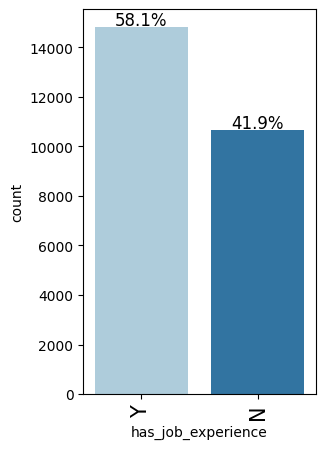

                      count  percentage
has_job_experience                     
Y                  14802.00       58.09
N                  10678.00       41.91
TOTALS             25480.00      100.00


In [25]:
#C24
labeled_barplot(df, 'has_job_experience', perc=True)
print(value_counts_perc(df,'has_job_experience'))

####requires_job_training
89% of applicants have job training


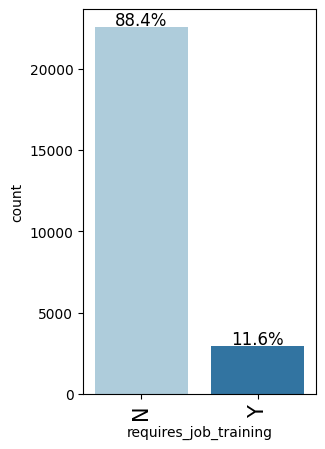

                         count  percentage
requires_job_training                     
N                     22525.00       88.40
Y                      2955.00       11.60
TOTALS                25480.00      100.00


In [26]:
#C25
labeled_barplot(df, 'requires_job_training', perc=True)
print(value_counts_perc(df,'requires_job_training'))

####no_of_employees
Data is right skewed and will need treatment. This code is in the data preprossing section.



                   count    mean      std    min     25%     50%     75%  \
no_of_employees 25480.00 5667.04 22877.93 -26.00 1022.00 2109.00 3504.00   

                      max  
no_of_employees 602069.00  


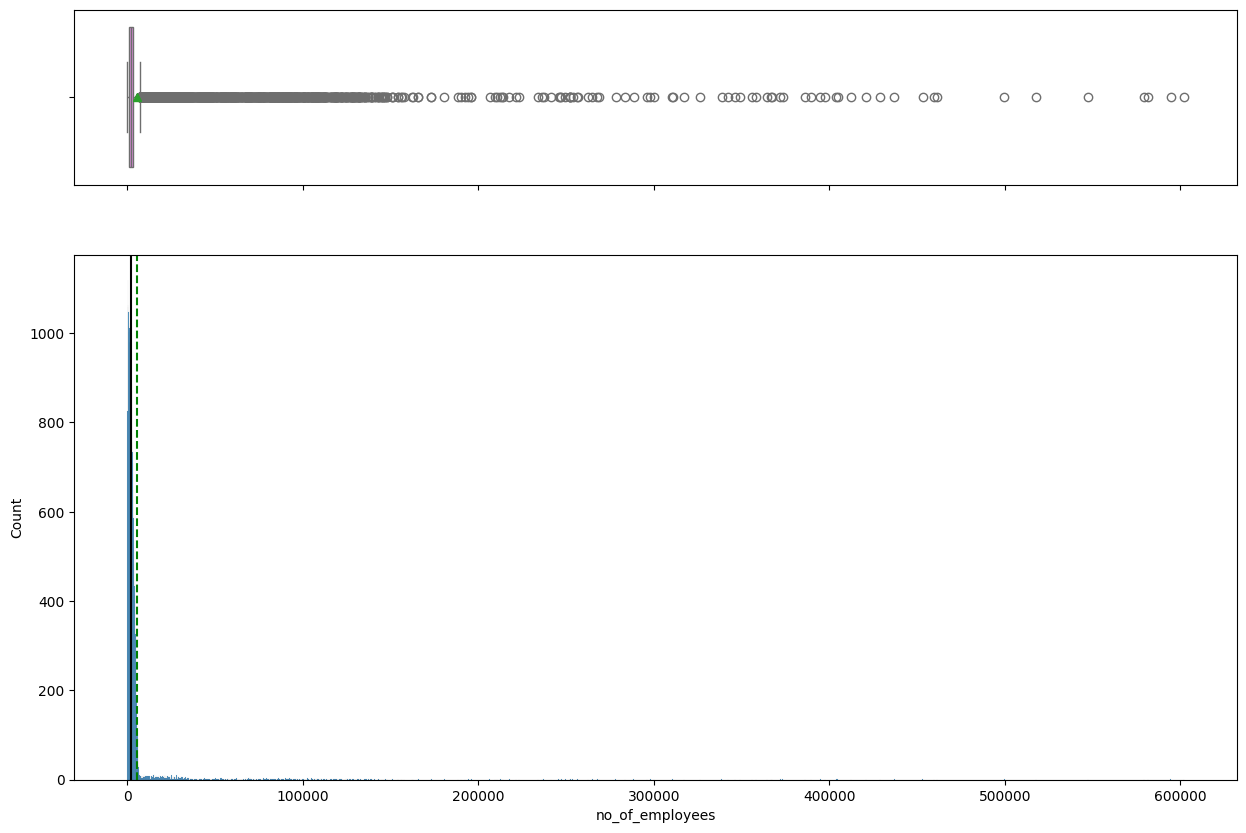

In [27]:
#C26
histogram_boxplot(df, 'no_of_employees' )
print(df[['no_of_employees']].describe().T)

In [28]:
#C27
#investigate negative (-26) employees

print(df.loc[df["no_of_employees"] < 0, "no_of_employees"].value_counts().sort_index().to_string())
print("n =", (df["no_of_employees"] < 0).sum())


#pattern fits a flipped sign on a small firm better than a missing-value code.
#Absolute value would turn them into firms of 11 to 26 employees. Dropping them would remove 33 applications.

no_of_employees
-26    7
-25    5
-17    4
-14    8
-11    9
n = 33


####yr_of_estab
Data is left skewed with outliers.
Field defined as number of year the firm is in operation.



               count    mean   std     min     25%     50%     75%     max
yr_of_estab 25480.00 1979.41 42.37 1800.00 1976.00 1997.00 2005.00 2016.00


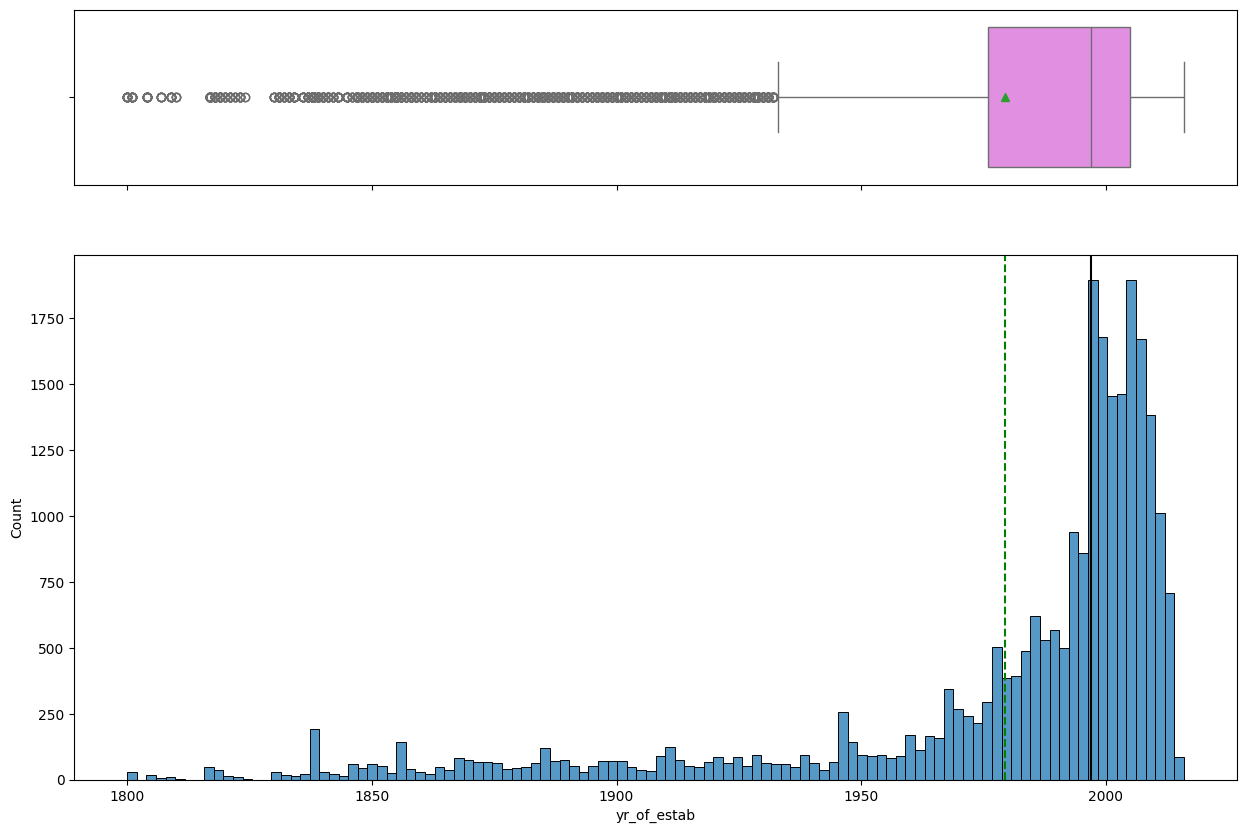

In [29]:
#C28

histogram_boxplot(df, 'yr_of_estab' )
print(df[['yr_of_estab']].describe().T)

####region_of_employment


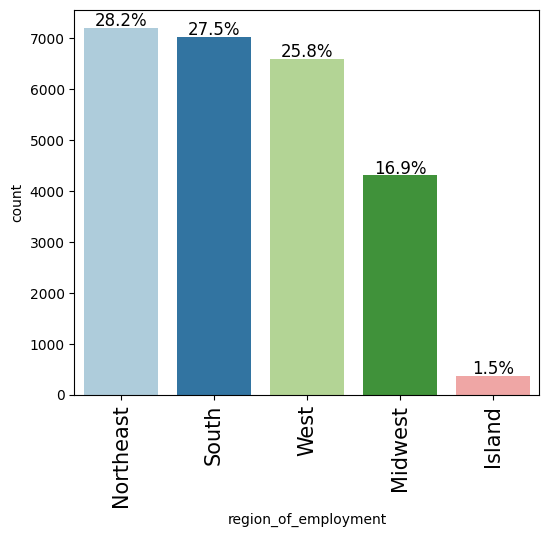

                        count  percentage
region_of_employment                     
Northeast             7195.00       28.24
South                 7017.00       27.54
West                  6586.00       25.85
Midwest               4307.00       16.90
Island                 375.00        1.47
TOTALS               25480.00      100.00


In [30]:
#C29
labeled_barplot(df, 'region_of_employment', perc=True)
print(value_counts_perc(df,'region_of_employment'))

#### prevailing_wage

* The histogram mixes hour, week, month, and year. The mean, 74,456, is not a yearly wage.
* Minimum 2.14 and maximum 319,210 are not on the same scale.
* Hours and days are unknown.
* Keep unit_of_wage and compare with case_status in the bivariate section.
* A conversion, if done later, needs a stated assumption and a reason.

                   count     mean      std  min      25%      50%       75%  \
prevailing_wage 25480.00 74455.81 52815.94 2.14 34015.48 70308.21 107735.51   

                      max  
prevailing_wage 319210.27  


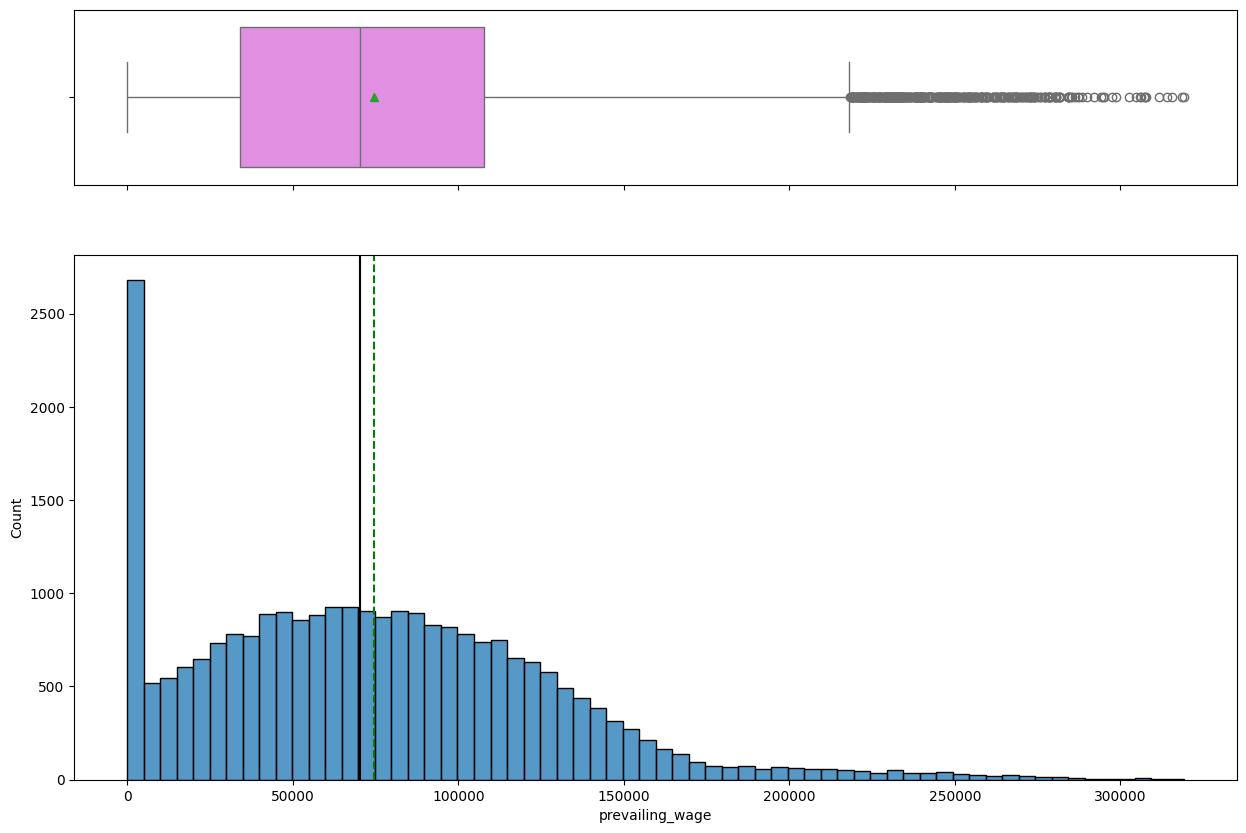

In [31]:
#C30
histogram_boxplot(df, 'prevailing_wage' )
print(df[['prevailing_wage']].describe().T)


* Comparing  unit_of_wage  to  prevailing_wage *


 unit_of_wage  index    Hour     Month      Week      Year
0             count 2157.00     89.00    272.00  22962.00
1              mean  414.57  87592.86  85606.82  81228.08
2               std  275.02  59525.12  44802.70  49951.47
3               min    2.14   1599.28   2183.23    100.00
4               25%  152.70  44986.24  51408.28  43715.96
5               50%  372.65  81826.01  85075.82  76174.50
6               75%  637.31 121629.60 111331.91 111341.96
7               max  999.92 264362.95 280175.95 319210.27 



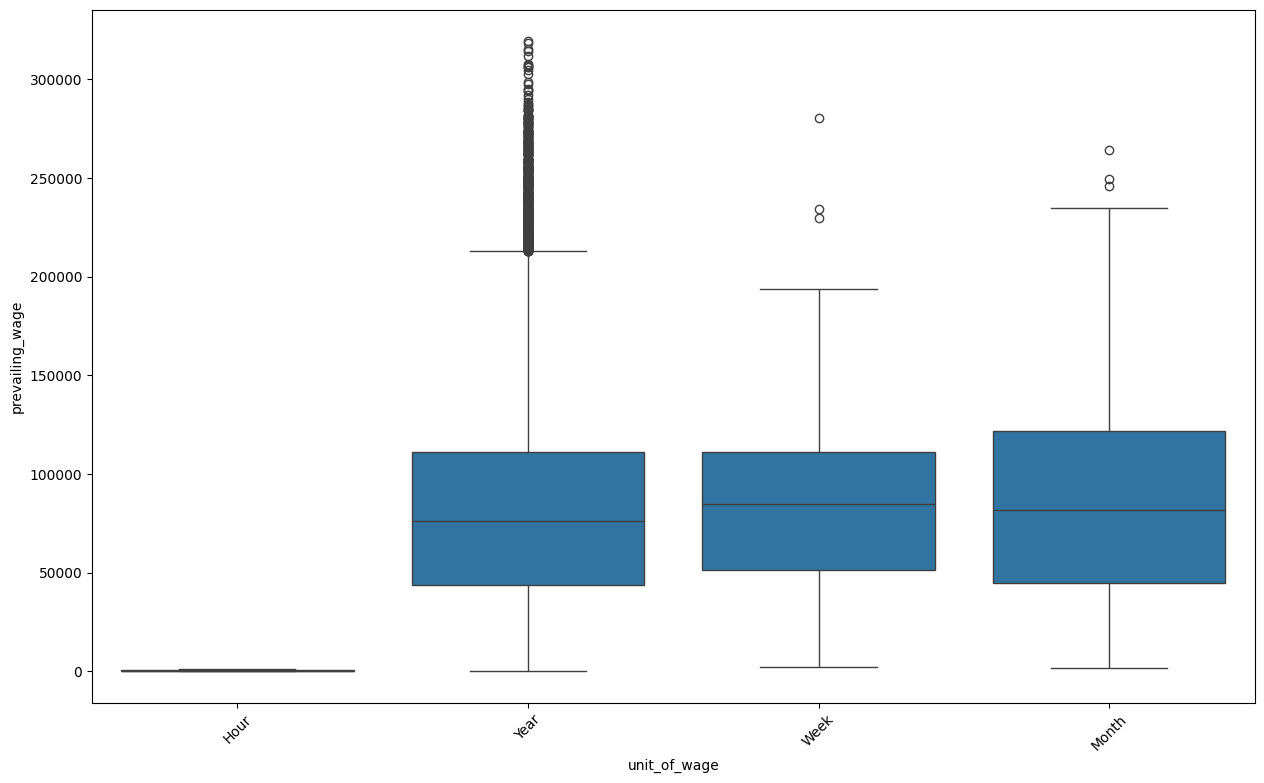

In [32]:
#C31

category_boxplot(df, 'unit_of_wage', 'prevailing_wage', hhue="empty", wider=0, taller=0)

#Week, month, and year sit on a similar scale. Hour does not.

In [33]:
#C32
print(pd.crosstab(df["unit_of_wage"], df["full_time_position"], margins=True).to_string())

full_time_position     N      Y    All
unit_of_wage                          
Hour                  19   2138   2157
Month                  5     84     89
Week                  10    262    272
Year                2673  20289  22962
All                 2707  22773  25480


#### unit_of_wage

* Year is 22,962 rows, 90.12 percent. That is the largest cohort.
* Hour is 2,157 rows, 8.47 percent. It is the second largest, and it is on a different scale.
* Week is 272. Month is 89. Both are thin for a later rate.
* Full-time versus part-time is a different split. Hour is almost all full-time. Part-time is almost all Year.
* Do not annualize. The unit stays in the file for the bivariate plot against case_status.

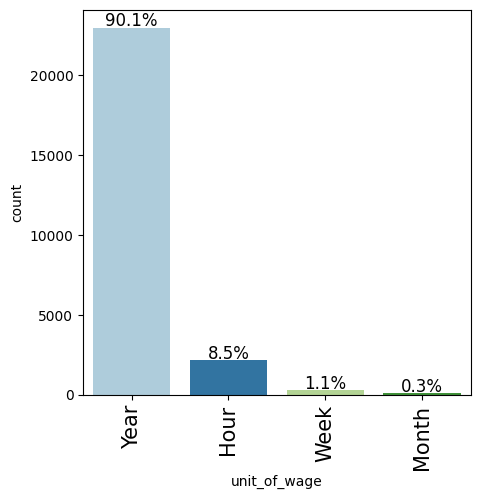

                count  percentage
unit_of_wage                     
Year         22962.00       90.12
Hour          2157.00        8.47
Week           272.00        1.07
Month           89.00        0.35
TOTALS       25480.00      100.00


In [34]:
#C33
labeled_barplot(df, 'unit_of_wage', perc=True)
print(value_counts_perc(df,'unit_of_wage'))

####full_time_position
Y is 22,773 (89.38 percent). N is 2,707 (10.62 percent). The total is 25,480 and 100 percent. Both match the crosstab margins.


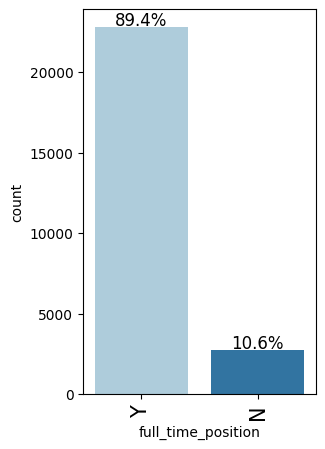

                      count  percentage
full_time_position                     
Y                  22773.00       89.38
N                   2707.00       10.62
TOTALS             25480.00      100.00


In [35]:
#C34
labeled_barplot(df, 'full_time_position', perc=True)
print(value_counts_perc(df,'full_time_position'))

####case_status
Certified is 17,018 (66.79 percent). Denied is 8,462 (33.21 percent). The total is 25,480 and 100 percent.

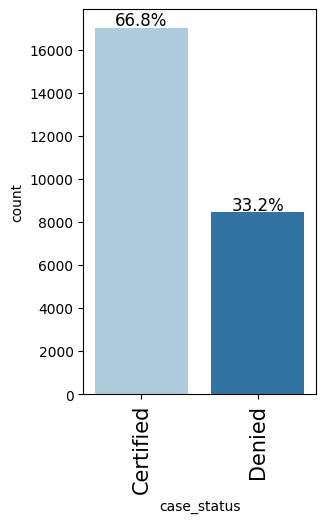

               count  percentage
case_status                     
Certified   17018.00       66.79
Denied       8462.00       33.21
TOTALS      25480.00      100.00


In [36]:
#C35
labeled_barplot(df, 'case_status', perc=True)
print(value_counts_perc(df,'case_status'))

###Bivariate Analysis

####Correlation check


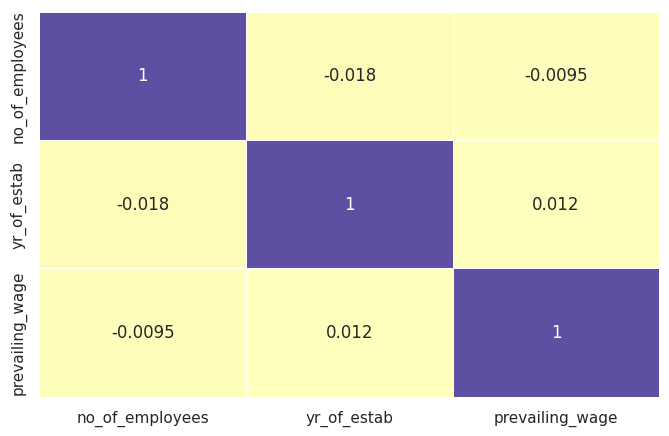

                 no_of_employees  yr_of_estab  prevailing_wage
no_of_employees             1.00        -0.02            -0.01
yr_of_estab                -0.02         1.00             0.01
prevailing_wage            -0.01         0.01             1.00


In [37]:
#C36

sns.set(rc={"figure.figsize": (8, 5)})
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    linewidths=0.5,
    center=0,
    cbar=False,
    cmap="Spectral",
)
plt.show()


print(df.corr(numeric_only=True).to_string())

#the numerics are independent

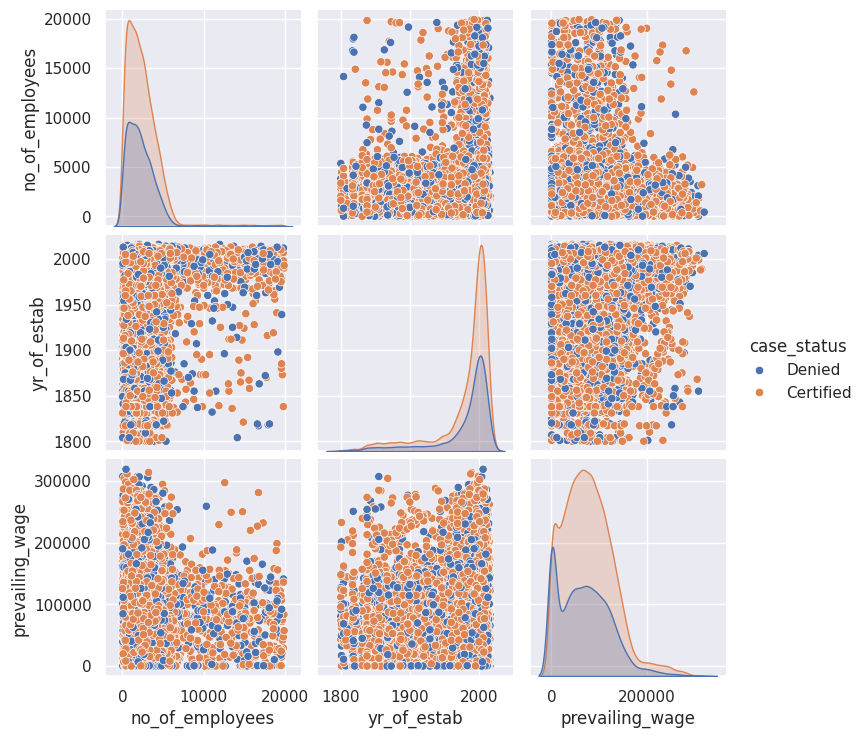

rows in view: 24382 of 25480


In [38]:
#C37
plot_df = df[df["no_of_employees"].between(0, 20000)]
sns.pairplot(plot_df, hue="case_status")
plt.show()
print("rows in view:", len(plot_df), "of", len(df))

#between(0, 20000) drops the 33 negatives and the far right tail from the picture only.

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


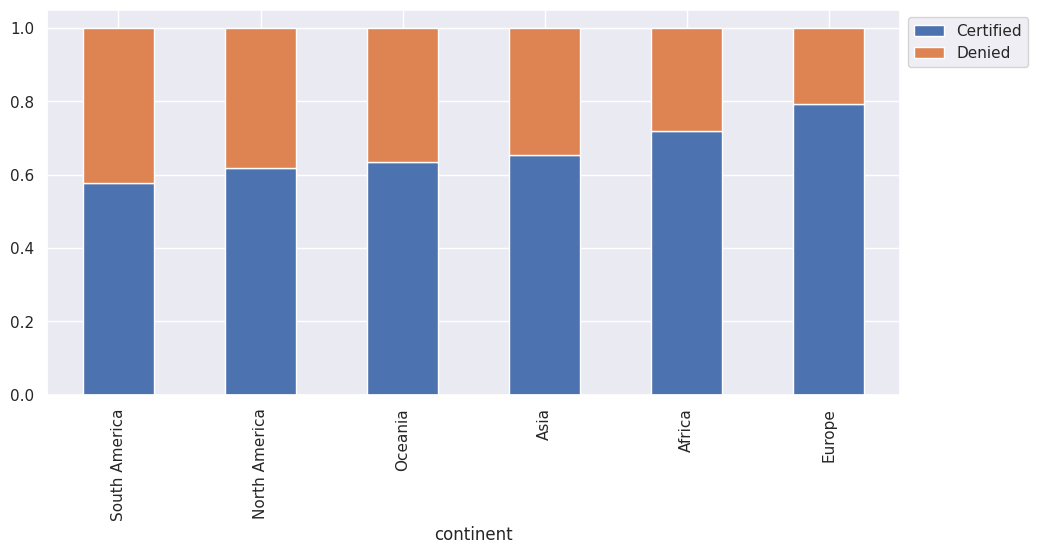

In [39]:
#C38
stacked_barplot(df, "continent", "case_status")

#### Observation on the correlation check

* Three numeric columns are in the matrix: no_of_employees, yr_of_estab, and prevailing_wage. case_status is text, so it is absent.
* Employee size and year founded: -0.02.
* Employee size and prevailing wage: -0.01.
* Year founded and prevailing wage: 0.01.
* These are noise-level coefficients. They do not support "smaller firms pay more" or "older firms are larger."
* prevailing_wage is still mixed units, so the -0.01 is not a yearly-wage effect.
* Nothing here is strong enough to drop a column for collinearity.


#### continent              vs case_status
Observation
Europe has the highest approval rate but all the continents are running between ~58% to 78%. Also there is a large varation in the volume of cases between the two highest continents.

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


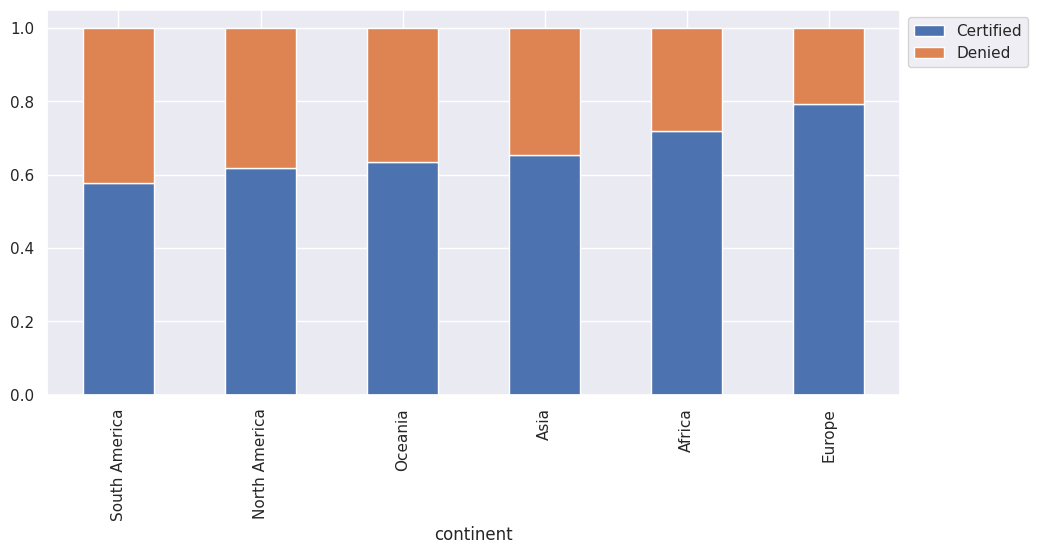

In [40]:
#C38
stacked_barplot(df,'continent', 'case_status')

#### education_of_employee  vs case_status
Observation:
* an obvious linear relationship between education level and liklihood of certification. The more education the more likely your application will be approved. Approx 85% of Doctorates are certified compared to only approx 35% of high school educated.

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


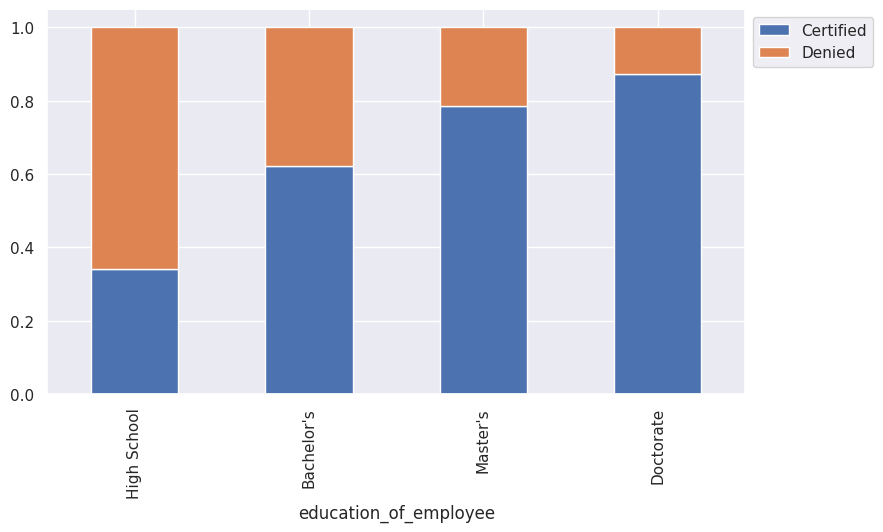

In [41]:
#C39
stacked_barplot(df,'education_of_employee', 'case_status')

#### has_job_experience     vs case_status
Observations
* Job experience has over 75% Certified so it certainly helps but not as profoundly as education.
* More than 50% of those that list no experience are certified      

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


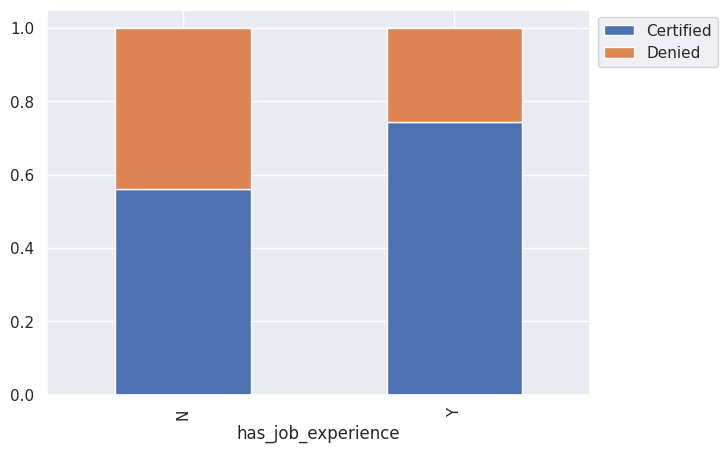

In [42]:
#C41
stacked_barplot(df,'has_job_experience', 'case_status')

#### requires_job_training  vs case_status
This cell shows training does not separate certified from denied the way education and experience do.  A later model may use this column.  

case_status            Certified  Denied    All
requires_job_training                          
All                        17018    8462  25480
N                          15012    7513  22525
Y                           2006     949   2955
------------------------------------------------------------------------------------------------------------------------


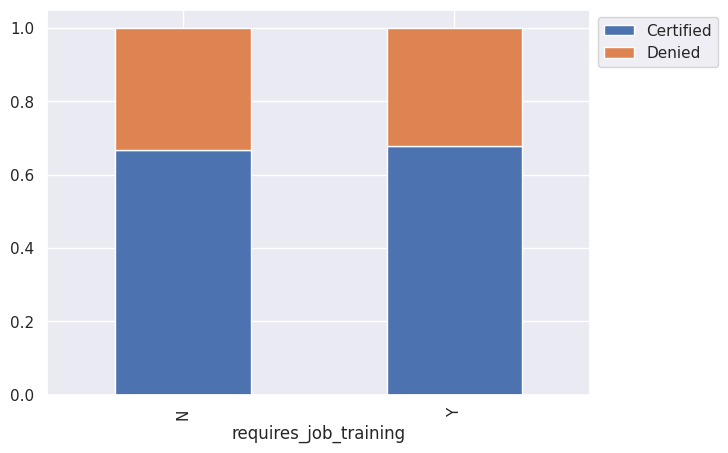

In [43]:
#C42
stacked_barplot(df,'requires_job_training', 'case_status')

#### region_of_employment   vs case_status

This cell shows the job's region separates the rate. It does not show why the Midwest is higher. Education mix inside each region is still unknown.

case_status           Certified  Denied    All
region_of_employment                          
All                       17018    8462  25480
Northeast                  4526    2669   7195
West                       4100    2486   6586
South                      4913    2104   7017
Midwest                    3253    1054   4307
Island                      226     149    375
------------------------------------------------------------------------------------------------------------------------


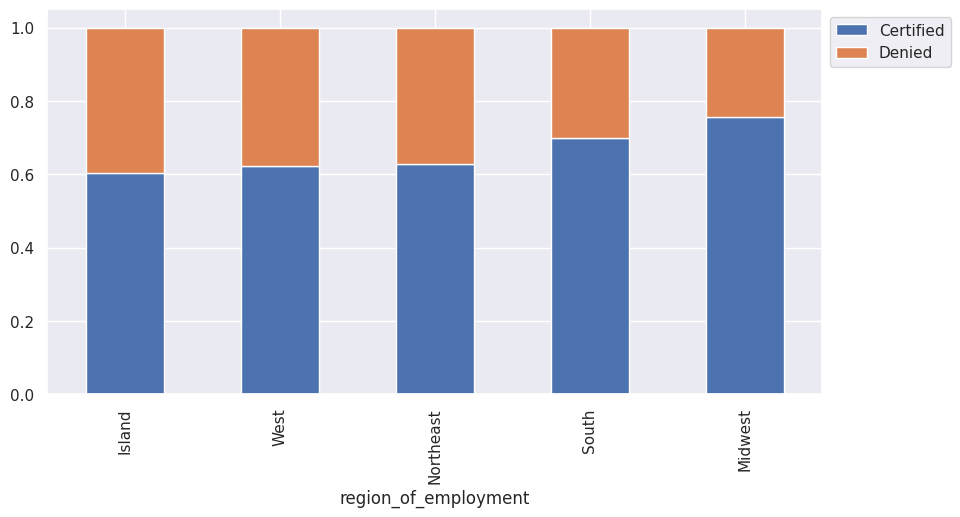

In [44]:
#C43
stacked_barplot(df,'region_of_employment', 'case_status')

#### unit_of_wage           vs case_status
This cell shows the wage unit separates certified from denied, mainly through Hour versus Year. It does not show that a higher wage causes certification. The wage is still on mixed scales.

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


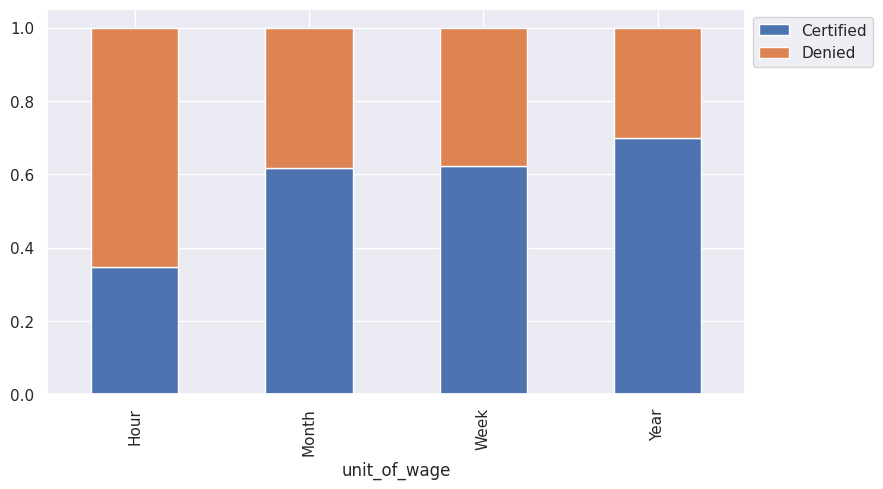

In [45]:
#C44
stacked_barplot(df,'unit_of_wage', 'case_status')

#### full_time_position     vs case_status
Schedule is not a separator the way education, experience, and the hourly unit are.

case_status         Certified  Denied    All
full_time_position                          
All                     17018    8462  25480
Y                       15163    7610  22773
N                        1855     852   2707
------------------------------------------------------------------------------------------------------------------------


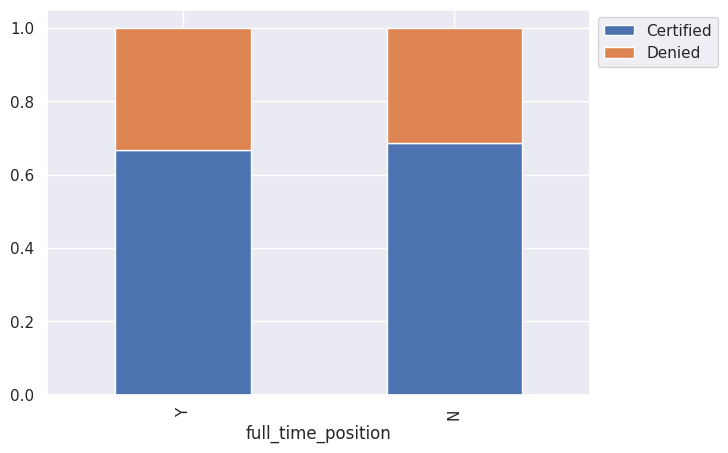

In [46]:
#C45
stacked_barplot(df,'full_time_position', 'case_status')

### **Leading Questions**:


#### 1. Those with higher education may want to travel abroad for a well-paid job. Does education play a role in visa certification?

Yes. The certification rate rises with education.

* High School: 1,164 / 3,420 = 34.0 percent.
* Bachelor's: 6,367 / 10,234 = 62.2 percent.
* Master's: 7,575 / 9,634 = 78.6 percent.
* Doctorate: 1,912 / 2,192 = 87.2 percent.

The jumps shrink as education rises: about 28 points, then 16, then 9. It is an ordered rise. Doctorate is the smallest base, still large enough to trust.

This shows education separates certified from denied. It does not show that education is the only driver. Experience and wage unit are still mixed inside each degree.

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


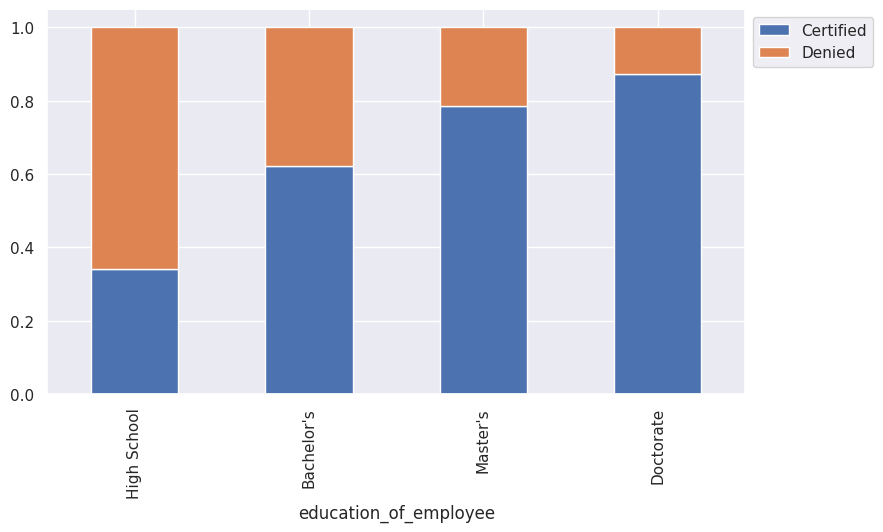

In [47]:
#c46
stacked_barplot(df, 'education_of_employee', 'case_status')

#### 2. How does the visa status vary across different continents?

Asia has the largest volume. Europe has the highest certification rate.

* Europe: 2,957 / 3,732 = 79.2 percent.
* Africa: 397 / 551 = 72.1 percent.
* Asia: 11,012 / 16,861 = 65.3 percent. Near the overall 66.8 percent, and most of the file.
* Oceania: 122 / 192 = 63.5 percent. Thin base.
* North America: 2,037 / 3,292 = 61.9 percent.
* South America: 493 / 852 = 57.9 percent. Lowest rate.

The print is sorted by denied count, so Asia is first because it has the most denials, not the worst rate. A high European rate may still be a different education mix. This plot does not separate those.

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


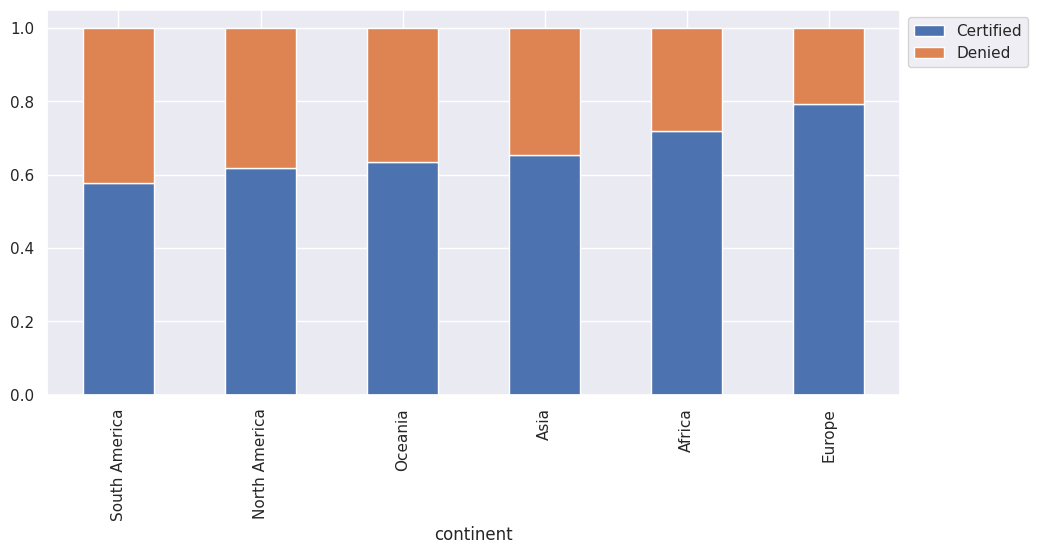

In [48]:
#C47
stacked_barplot(df, 'continent', 'case_status')

#### 3. Experienced professionals might look abroad for opportunities to improve their lifestyles and career development. Does work experience influence visa status?

Yes. Experience raises the certification rate.

* Experience Y: 11,024 / 14,802 = 74.5 percent.
* Experience N: 5,994 / 10,678 = 56.1 percent.
* The gap is about 18 points. Both bases are large.

Education's spread was wider, from 34 percent to 87 percent. Experience still separates the cases. It does not show experience apart from education. A Master's with no experience may still clear a High School case with experience.

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


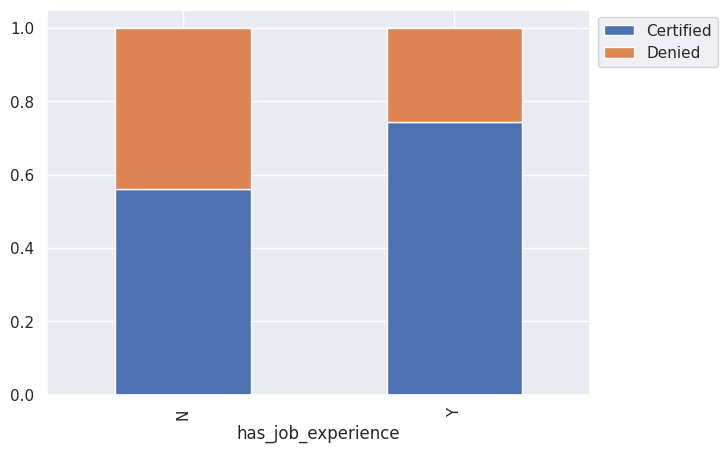

In [49]:
#C48
stacked_barplot(df, 'has_job_experience', 'case_status')

#### 4. In the United States, employees are paid at different intervals. Which pay unit is most likely to be certified for a visa?

Year. Hour is the group that falls away.

* Year: 16,047 / 22,962 = 69.9 percent.
* Week: 169 / 272 = 62.1 percent.
* Month: 55 / 89 = 61.8 percent.
* Hour: 747 / 2,157 = 34.6 percent.

Week and month are close, on thin bases. Hour is about half the Year rate. That is a unit effect, not a correlation, and not a straight progression from hour to year.

This is why prevailing_wage was not converted to a yearly wage. Folding Hour into Year would hide the group certified at 35 percent.

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


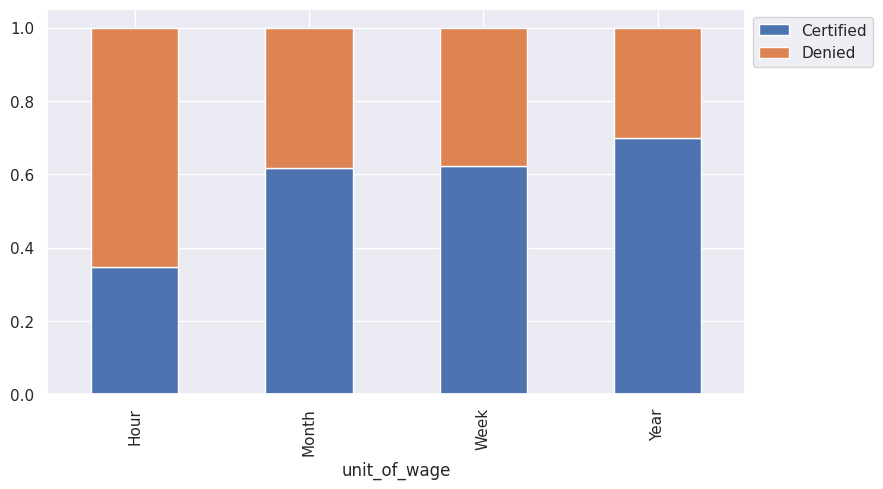

In [50]:
#C49
stacked_barplot(df, 'unit_of_wage', 'case_status')

#### 5. The United States (US) government has established a prevailing wage to protect local talent and foreign workers. How does the visa status change with the prevailing wage?

Certified cases sit higher on the raw wage axis. That is not a clean income effect.

* Certified median 72,486. Denied median 65,431.
* Certified first quartile 38,375. Denied first quartile 23,497.
* Both sides still run from about 2 to about 319,000. The scales are mixed.

Hour was certified at 34.6 percent, and hourly amounts sit at the low end of this axis. The lower Denied quartile is consistent with that mix. Do not read this plot as "higher wage, higher certification" until the unit is held constant.


* Comparing  case_status  to  prevailing_wage *


 case_status  index  Certified    Denied
0            count   17018.00   8462.00
1             mean   77293.62  68748.68
2              std   52042.72  53890.17
3              min       2.14      2.96
4              25%   38375.33  23497.29
5              50%   72486.27  65431.46
6              75%  108879.11 105097.64
7              max  318446.05 319210.27 



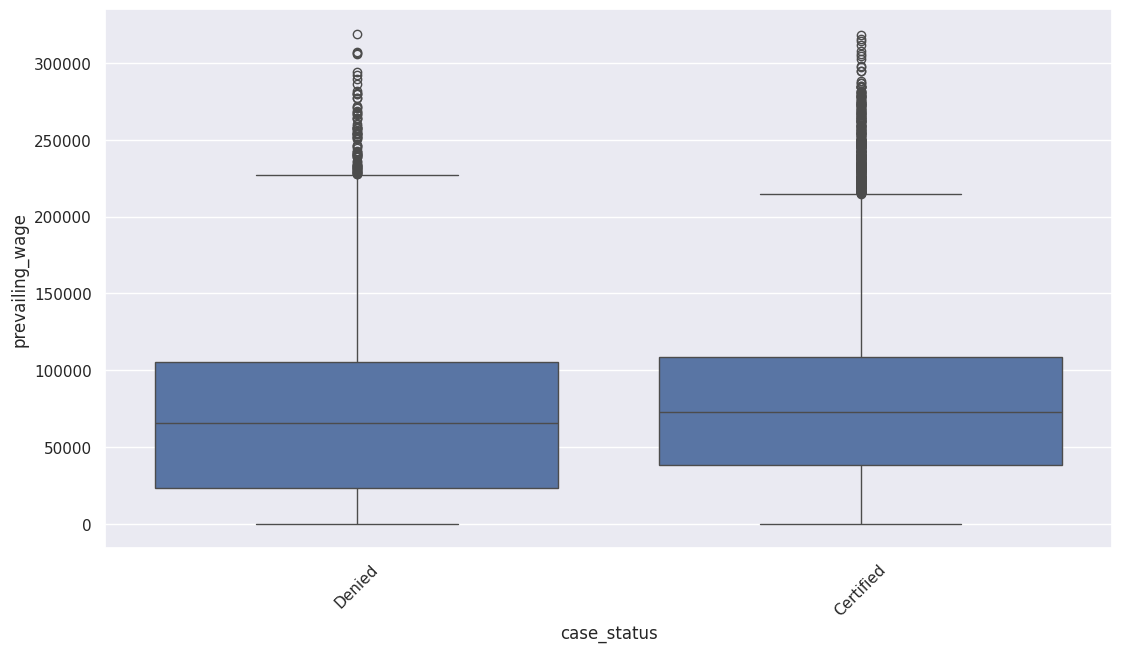

In [51]:
#C50
category_boxplot(df, 'case_status', 'prevailing_wage', hhue="empty", wider=-2, taller=-2)

## Data Preprocessing


###Duplicate Check
C21 printed 0 duplicate rows and 0 duplicate case_id values.

###Missing value treatment
C19 and C20 showed 0 missing in every column. Every column had 25,480 non-null rows



### Outlier detection and treatment

Boxplots show points outside the whiskers on all three numeric columns. A point outside the whisker is not automatically a bad value. We do not cap by the interquartile range (IQR).

* no_of_employees: the right tail runs to 602,069. A large firm can be real. Capping would flatten valid employers. The 33 negative values cannot be a headcount. Those rows are a separate decision: absolute value, if we assume only the sign is wrong, or drop the 33 rows.
* yr_of_estab: the left tail runs to 1800. An old founding year can be real.
* prevailing_wage: the plot mixes hour, week, month, and year. A low point and a high point are not the same kind of outlier.

Trees split on rank. A long tail does not have to be forced into a symmetric shape before the model.

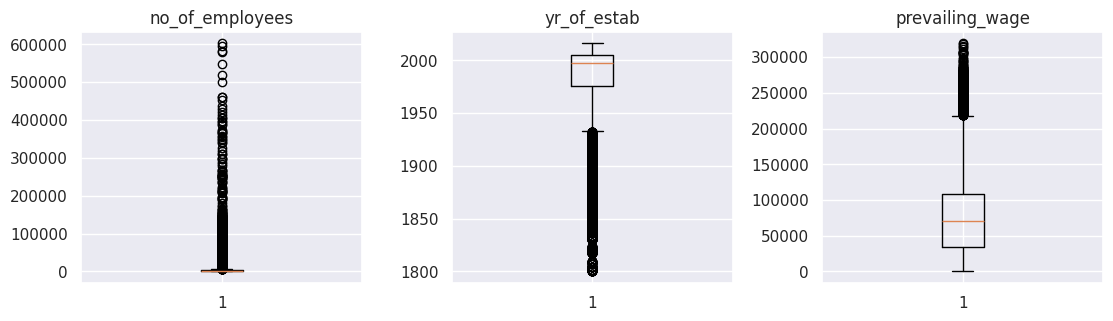

In [52]:
#C51
#  outlier detection using boxplot

numeric_cols = df.select_dtypes(include='number').columns.tolist()

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_cols):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

###Feature engineering

In [53]:
# C52
# 33 negative employee counts in no_of_employees is most likely a sign error
# We can take the absolute value, or drop those rows.
# we choose to take the absolute value
# Update the 'no_of_employees' column to its absolute value

df['no_of_employees'] = df['no_of_employees'].abs()
print("negatives left:", (df["no_of_employees"] < 0).sum())

negatives left: 0


In [54]:
#C53
# I elect to not build annual_prevailing_wage.
# Hours and days are unknown, and Hour is certified at 34.6 percent.
# Keep prevailing_wage and unit_of_wage. No new column.

##Preparing data for modeling

In [55]:
#C53
# Split 70/30. 70 percent train, 30 percent test.

df = df.drop(columns="case_id")
df["case_status"] = (df["case_status"] == "Certified").astype(int)

X = df.drop(columns="case_status")
y = df["case_status"]
X = pd.get_dummies(X, drop_first=True)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)


In [56]:
#C54
#confirm the shape of both data sets and the ratio of classes is the same across both train and test datasets
print('\n************')
print("Shape of Training set : ", x_train.shape)
print("Shape of test set : ", x_test.shape)
print('\n************')
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print('\n************')
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))
print('\n************')


************
Shape of Training set :  (17836, 21)
Shape of test set :  (7644, 21)

************
Percentage of classes in training set:
case_status
1   0.67
0   0.33
Name: proportion, dtype: float64

************
Percentage of classes in test set:
case_status
1   0.67
0   0.33
Name: proportion, dtype: float64

************


## Model evaluation criterion

A model can make two wrong predictions.

1. It predicts certified, and the application should be denied. This is a false certification. A foreign worker is selected over a United States (US) worker.
2. It predicts denied, and the application should be certified. This is a false denial. The US loses a worker the case should have cleared.

Both errors cost something. Worker protection and filling a real shortage both matter.

## Score

* Accuracy is a weak score. Certified is already about 67 percent of the file. A model that calls every case certified looks accurate and catches no denials.
* The F1 score balances precision and recall. It is the score we will tune on, because both false certifications and false denials matter.
* class_weight='balanced' makes the tree pay equal attention to both classes. It does not change the 0.5 cutoff used by predict.

## Decision Tree - Model Building and Hyperparameter Tuning

In [57]:

#C55
dtree = DecisionTreeClassifier(criterion='gini', random_state=1, class_weight='balanced')


In [58]:

#C56
print(dtree.fit(x_train, y_train))


DecisionTreeClassifier(class_weight='balanced', random_state=1)


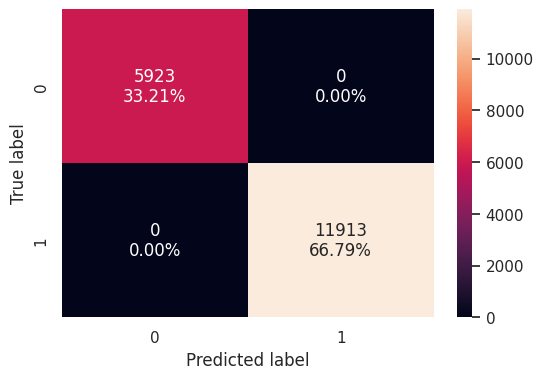

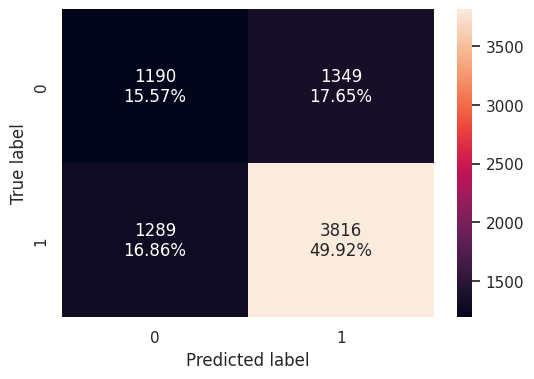

In [59]:

#C57
# create a confusion matrix of the classifier's performance on the testing data

confusion_matrix_sklearn(dtree, x_train, y_train)

confusion_matrix_sklearn(dtree, x_test, y_test)


##Confusion Matrix

* Applicant was approved and the model predicted approval :  True Positive
 observed=1 and predicted=1

* Applicant was denied and the model predicted approval : False Positive observed=0 and predicted=1

* Applicant was denied and the model predicted denial : True Negative observed=0 and predicted=0

* Applicant was approved and the model predicted denial : False Negative observed=1 and predicted=0

In [60]:

#C57.4
dtree_model_train_perf=model_performance_classification_sklearn(dtree, x_train, y_train)
print("Training performance... \n",dtree_model_train_perf)


Training performance... 
    Accuracy  Recall  Precision   F1
0      1.00    1.00       1.00 1.00


In [61]:

#C57.7
dtree_model_test_perf=model_performance_classification_sklearn(dtree, x_test, y_test)
print("Testing performance... \n",dtree_model_test_perf)


Testing performance... 
    Accuracy  Recall  Precision   F1
0      0.65    0.75       0.74 0.74


##Decision Tree
The model is working well on training data but is lost performance on testing. This indicates over fitting

## Building bagging and boosting models

In [62]:

#C58
bagging = BaggingClassifier(random_state=1)
bagging.fit(x_train,y_train)


BaggingClassifier(random_state=1)

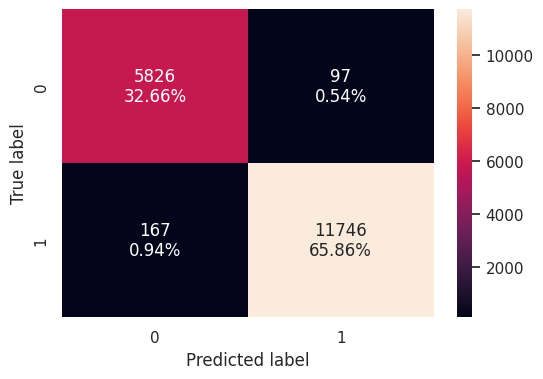

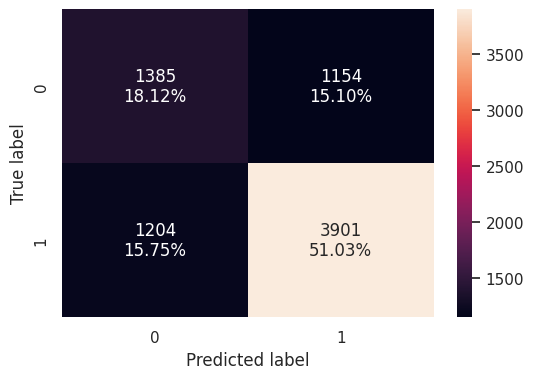

In [63]:

#C59
#create a confusion matrix of the classifier's performance on the testing data
confusion_matrix_sklearn(bagging, x_train, y_train)
confusion_matrix_sklearn(bagging, x_test, y_test)


In [64]:

#C60
bagging_model_train_perf=model_performance_classification_sklearn(bagging, x_train, y_train)
print("Training performance... \n",bagging_model_train_perf)


Training performance... 
    Accuracy  Recall  Precision   F1
0      0.99    0.99       0.99 0.99


In [65]:

#C61
bagging_model_test_perf=model_performance_classification_sklearn(bagging, x_test, y_test)
print("Testing performance \n",bagging_model_test_perf)


Testing performance 
    Accuracy  Recall  Precision   F1
0      0.69    0.76       0.77 0.77


### Bagging

* Train F1 is 0.99. Test F1 is 0.77. The model is overfitting.
* Test accuracy is 0.69. That clears the 67 percent rule of calling every case certified. The unrestricted tree did not.
* Bagging smoothed the single tree. It did not remove the gap. The tune is later.
* Quote the test F1, 0.77. Do not quote the train 0.99.

##Random Forest

In [66]:

#C62
rf = RandomForestClassifier(random_state=1)
rf.fit(x_train,y_train)



RandomForestClassifier(random_state=1)

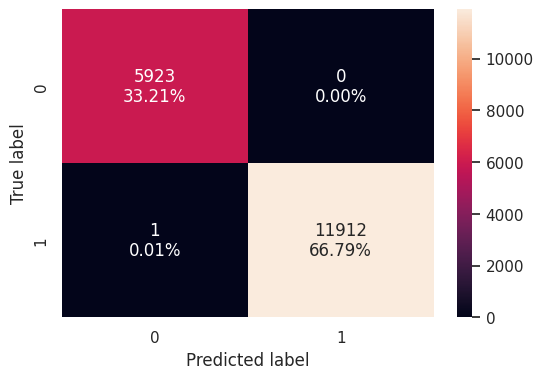

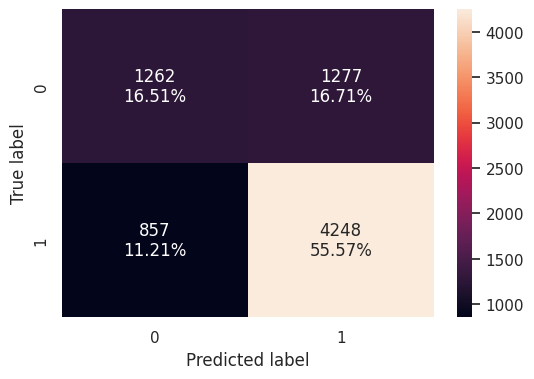

In [67]:

#C63
# create a confusion matrix of the classifier's performance on the testing data
confusion_matrix_sklearn(rf, x_train, y_train)
confusion_matrix_sklearn(rf, x_test, y_test)


In [68]:

#C64
rf_model_train_perf=model_performance_classification_sklearn(rf,x_train,y_train)
print("Training performance \n",rf_model_train_perf)


Training performance 
    Accuracy  Recall  Precision   F1
0      1.00    1.00       1.00 1.00


In [69]:

#C65
rf_model_test_perf=model_performance_classification_sklearn(rf,x_test,y_test)
print("Testing performance \n",rf_model_test_perf)


Testing performance 
    Accuracy  Recall  Precision   F1
0      0.72    0.83       0.77 0.80


### Random Forest

* Train F1 is 1.00. Test F1 is 0.80. The model is overfitting.
* Test accuracy is 0.72, recall 0.83, precision 0.77.
* Best test F1 so far. The unrestricted tree missed the 67 percent bar. Bagging was 0.77.
* Quote the test F1, 0.80. Do not quote the train 1.00.

##AdaBoost Classifier


In [70]:

#C66
ab_classifier=AdaBoostClassifier(random_state=1)
ab_classifier.fit(x_train,y_train)


AdaBoostClassifier(random_state=1)

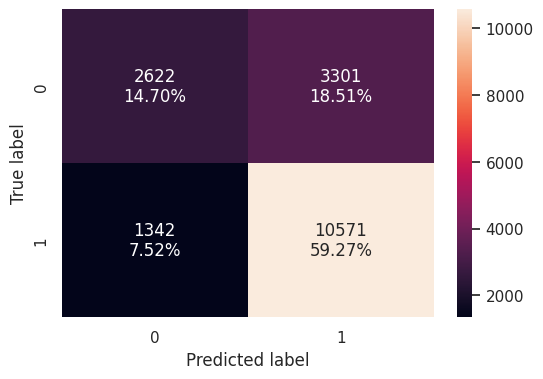

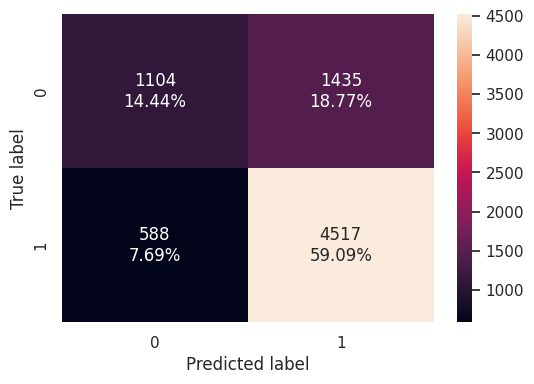

In [71]:

#C67
#create a confusion matrix of the classifier's performance on the testing data
confusion_matrix_sklearn(ab_classifier, x_train, y_train)
confusion_matrix_sklearn(ab_classifier, x_test, y_test)



In [72]:

#C68
ab_classifier_model_train_perf = model_performance_classification_sklearn(ab_classifier,x_train,y_train)
print("Training performance \n",ab_classifier_model_train_perf)


Training performance 
    Accuracy  Recall  Precision   F1
0      0.74    0.89       0.76 0.82


In [73]:

#C69
ab_classifier_model_test_perf = model_performance_classification_sklearn(ab_classifier,x_test,y_test)
print("Testing performance \n",ab_classifier_model_test_perf)


Testing performance 
    Accuracy  Recall  Precision   F1
0      0.74    0.88       0.76 0.82


### AdaBoost

* This is the base Adaptive Boosting (AdaBoost) model. It has not been tuned.
* Train F1 is 0.82. Test F1 is 0.82. Accuracy is 0.74 on both. The model is not overfitting.
* Best test F1 so far. Random forest was 0.80, with a train F1 of 1.00.
* Test recall 0.88, precision 0.76. More false certifications than the forest, fewer false denials.
* Quote the test F1, 0.82.

##Gradient Boosting Classifier

In [74]:

#C70
# Choose the type of classifier.
gbc = GradientBoostingClassifier(random_state=1)
gbc.fit(x_train,y_train)


GradientBoostingClassifier(random_state=1)

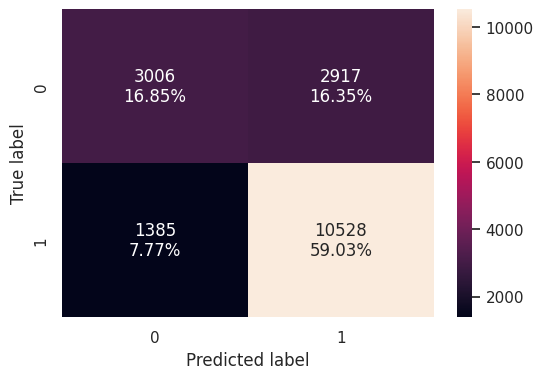

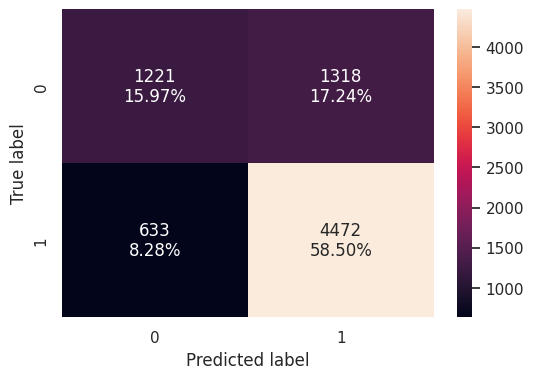

In [75]:

#C71
#create a confusion matrix of the classifier's performance on the testing data
confusion_matrix_sklearn(gbc, x_train, y_train)
confusion_matrix_sklearn(gbc, x_test, y_test)


In [76]:

#C72
gbc_classifier_model_train_perf = model_performance_classification_sklearn(gbc,x_train,y_train)
print("Training performance,,, \n",gbc_classifier_model_train_perf)


Training performance,,, 
    Accuracy  Recall  Precision   F1
0      0.76    0.88       0.78 0.83


In [77]:

#C73
gbc_classifier_model_test_perf = model_performance_classification_sklearn(gbc,x_test,y_test)
print("Training performance... \n",gbc_classifier_model_test_perf)


Training performance... 
    Accuracy  Recall  Precision   F1
0      0.74    0.88       0.77 0.82


### Gradient Boosting

* This is the base gradient boosting model. It has not been tuned.
* Train F1 is 0.83. Test F1 is 0.82. The gap is one point. The model is not overfitting.
* Test accuracy 0.74, recall 0.88, precision 0.77.
* Test F1 ties AdaBoost at 0.82. Both beat the forest's 0.80.
* Quote the test F1, 0.82.

##XGBoost Classifer

In [78]:

#C74
xgb = XGBClassifier(random_state=1,eval_metric='logloss')
xgb.fit(x_train,y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

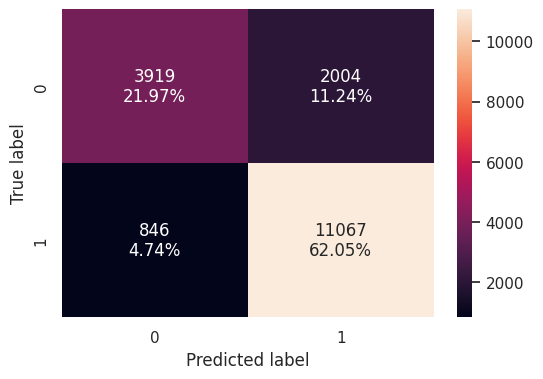

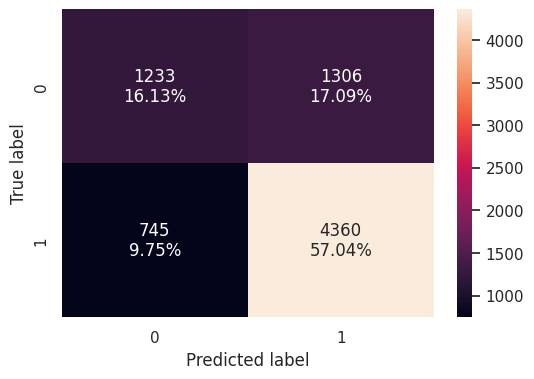

In [79]:

#C75
#create a confusion matrix of the classifier's performance on the  data
confusion_matrix_sklearn(xgb, x_train, y_train)
confusion_matrix_sklearn(xgb, x_test, y_test)


In [80]:

#C76
xgb_classifier_model_train_perf = model_performance_classification_sklearn(xgb,x_train,y_train)
print("Training performance... \n",xgb_classifier_model_train_perf)


Training performance... 
    Accuracy  Recall  Precision   F1
0      0.84    0.93       0.85 0.89


In [81]:


#C77
xgb_classifier_model_test_perf = model_performance_classification_sklearn(xgb,x_test,y_test)
print("Test performance... \n",xgb_classifier_model_test_perf)


Test performance... 
    Accuracy  Recall  Precision   F1
0      0.73    0.85       0.77 0.81


### XGBoost

* This is the base Extreme Gradient Boosting (XGBoost) model. It has not been tuned.
* Train F1 is 0.89. Test F1 is 0.81. There is a gap. The model overfits, less than the forest.
* Test accuracy 0.73, recall 0.85, precision 0.77.
* Slightly under the 0.82 tie from AdaBoost and gradient boosting.
* Quote the test F1, 0.81.

##Base models comparison

In [82]:

#C77
# create a dataframe comparing the performance of the base models on the training data
# do not rank from this table. The tree, bagging, and the forest memorized the train rows. The ranking is the test table.

models_train_comp_df = pd.concat(
    [dtree_model_train_perf.T,
     bagging_model_train_perf.T,
     rf_model_train_perf.T,
     ab_classifier_model_train_perf.T,
     gbc_classifier_model_train_perf.T,
     xgb_classifier_model_train_perf.T],
    axis=1,
)
models_train_comp_df.columns = [
    "Decision Tree",
    "Bagging Classifier",
    "Random Forest",
    "AdaBoost Classifier",
    "Gradient Boosting Classifier",
    "XGBoost Classifier"]
print("Training performance comparison of base models:")
print(models_train_comp_df)



Training performance comparison of base models:
           Decision Tree  Bagging Classifier  Random Forest  \
Accuracy            1.00                0.99           1.00   
Recall              1.00                0.99           1.00   
Precision           1.00                0.99           1.00   
F1                  1.00                0.99           1.00   

           AdaBoost Classifier  Gradient Boosting Classifier  \
Accuracy                  0.74                          0.76   
Recall                    0.89                          0.88   
Precision                 0.76                          0.78   
F1                        0.82                          0.83   

           XGBoost Classifier  
Accuracy                 0.84  
Recall                   0.93  
Precision                0.85  
F1                       0.89  


In [83]:

#C78
# create a dataframe comparing the performance of the base models on the testing data
models_test_comp_df = pd.concat(
    [dtree_model_test_perf.T,
     bagging_model_test_perf.T,
     rf_model_test_perf.T,
     ab_classifier_model_test_perf.T,
     gbc_classifier_model_test_perf.T,
     xgb_classifier_model_test_perf.T],
    axis=1,
)
models_test_comp_df.columns = [
    "Decision Tree",
    "Bagging Classifier",
    "Random Forest",
    "AdaBoost Classifier",
    "Gradient Boosting Classifier",
    "XGBoost Classifier"]
print("Testing performance comparison of base models:")
print(models_test_comp_df)

Testing performance comparison of base models:
           Decision Tree  Bagging Classifier  Random Forest  \
Accuracy            0.65                0.69           0.72   
Recall              0.75                0.76           0.83   
Precision           0.74                0.77           0.77   
F1                  0.74                0.77           0.80   

           AdaBoost Classifier  Gradient Boosting Classifier  \
Accuracy                  0.74                          0.74   
Recall                    0.88                          0.88   
Precision                 0.76                          0.77   
F1                        0.82                          0.82   

           XGBoost Classifier  
Accuracy                 0.73  
Recall                   0.85  
Precision                0.77  
F1                       0.81  


### base models

* Rank on test F1 (not the train table).
* AdaBoost and gradient boosting tie at test F1 0.82. Both have almost no train-test gap.
* XGBoost is 0.81, with a gap. Random forest is 0.80, and it memorized train.
* Bagging is 0.77. The decision tree is 0.74, and its test accuracy of 0.65 misses the 67 percent rule.
* Tune AdaBoost and gradient boosting first. Extreme Gradient Boosting (XGBoost) stays optional.

## Hyperparameter tuning

###Tuning the decision tree

In [84]:
#C79
# Choose the type of classifier.
dtree_estimator = DecisionTreeClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {'max_depth': np.arange(5,30,5),
              'min_samples_leaf': [3, 5, 7],
              'max_leaf_nodes' : [2, 4, 6],
              'min_impurity_decrease': [0.0001,0.001,0.01,0.1]
             }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(dtree_estimator, parameters, scoring=scorer, cv=5)
grid_obj = grid_obj.fit(x_train, y_train)

# Set the clf to the best combination of parameters
dtree_estimator = grid_obj.best_estimator_

# Fit the best algorithm to the data.
print(dtree_estimator.fit(x_train, y_train))

DecisionTreeClassifier(max_depth=np.int64(5), max_leaf_nodes=4,
                       min_impurity_decrease=0.0001, min_samples_leaf=3,
                       random_state=1)


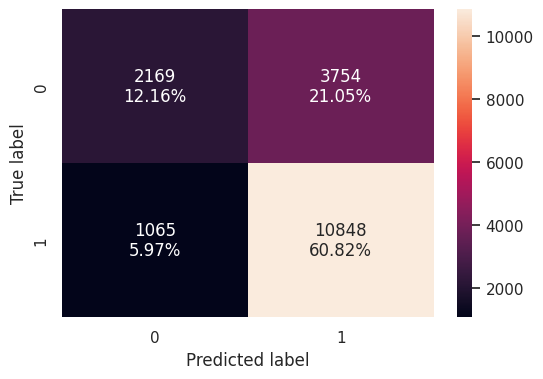

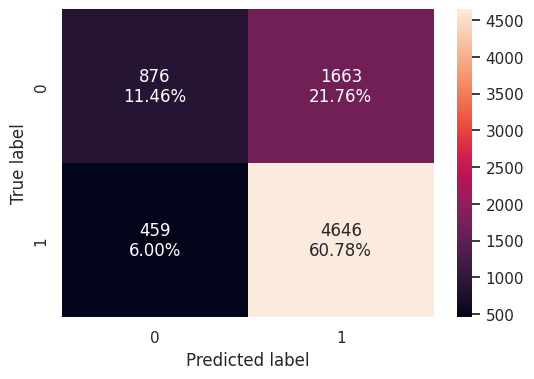

In [85]:
#C80
# create a onfusion matrix of the classifier's performance on the testing data
confusion_matrix_sklearn(dtree_estimator, x_train, y_train)
confusion_matrix_sklearn(dtree_estimator, x_test, y_test)

In [86]:
#C81
dtree_estimator_model_train_perf=model_performance_classification_sklearn(dtree_estimator, x_train,y_train)
print("Training performance \n",dtree_estimator_model_train_perf)

Training performance 
    Accuracy  Recall  Precision   F1
0      0.73    0.91       0.74 0.82


In [89]:
#C82
dtree_estimator_model_test_perf=model_performance_classification_sklearn(dtree_estimator, x_test, y_test)
print("Testing performance \n",dtree_estimator_model_test_perf)

Testing performance 
    Accuracy  Recall  Precision   F1
0      0.72    0.91       0.74 0.81


#### tuned decision tree

* Best tree: max_depth 5, max_leaf_nodes 4. A four-leaf tree.
* Train F1 0.82. Test F1 0.81. Not overfitting.
* Test accuracy 0.72, recall 0.91, precision 0.74.
* Better than the base tree (test F1 0.74, accuracy 0.65). One point under the AdaBoost and gradient boosting tie at 0.82.
* High recall, more false certifications. Quote the test F1, 0.81.

###Tuning the Bagging Classifier
Hyperparameters available for bagging classifier include:
   - base_estimator: The base estimator to fit on random subsets of the dataset. If None(default), then the base estimator is a decision tree.
   - n_estimators: The number of trees in the forest, default = 100.
   - max_features: The number of features to consider when looking for the best split.
   - bootstrap: Whether bootstrap samples are used when building trees. If False, the entire dataset is used to build each tree, default=True.
   - bootstrap_features: If it is true, then features are drawn with replacement. Default value is False.
   - max_samples: If bootstrap is True, then the number of samples to draw from X to train each base estimator. If None (default), then draw N samples, where N is the number of observations in the train data.
   - oob_score: Whether to use out-of-bag samples to estimate the generalization accuracy, default=False.

In [90]:
#C82 random search for bagging classifier
parameters = {'max_samples': [0.7,0.8,0.9,1],
              'max_features': [0.7,0.8,0.9,1],
              'n_estimators' : np.arange(50, 100, 10)
             }

#run the randomized search
rand_bag = RandomizedSearchCV(BaggingClassifier(random_state=1,bootstrap=True),
                              parameters, scoring = 'f1', cv = 5, random_state=1)
rand_bag = rand_bag.fit(x_train, y_train)

# Set the clf to the best combination of parameters
bag_tuned = rand_bag.best_estimator_

# Fit the best algorithm to the data
print(bag_tuned.fit(x_train, y_train))

BaggingClassifier(max_features=0.8, max_samples=0.8, n_estimators=np.int64(70),
                  random_state=1)


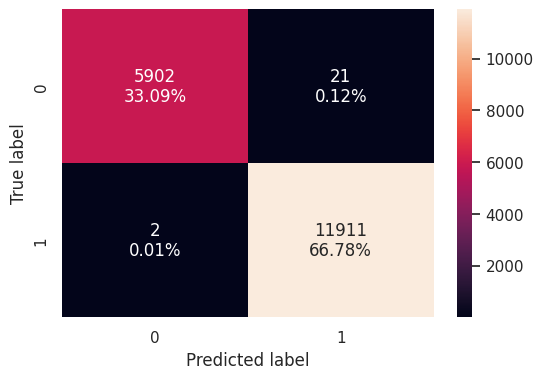

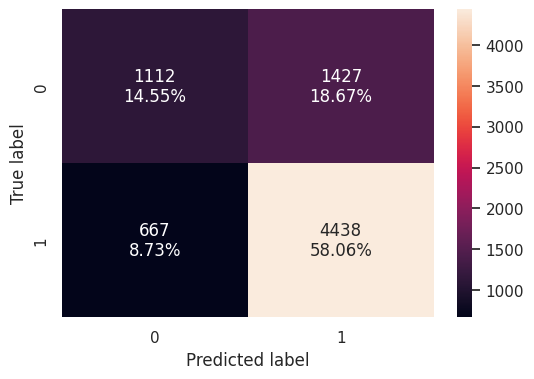

In [91]:
#C82
# create a confusion matrix of the classifier's performance on the testing data
confusion_matrix_sklearn(bag_tuned, x_train,y_train)
confusion_matrix_sklearn(bag_tuned, x_test,y_test)

In [92]:
#C83
bagging_estimator_model_train_perf=model_performance_classification_sklearn(bag_tuned, x_train,y_train)
print("Training performance \n",bagging_estimator_model_train_perf)

Training performance 
    Accuracy  Recall  Precision   F1
0      1.00    1.00       1.00 1.00


In [93]:
#C84
bagging_estimator_model_test_perf=model_performance_classification_sklearn(bag_tuned, x_test, y_test)
print("Testing performance \n",bagging_estimator_model_test_perf)

Testing performance 
    Accuracy  Recall  Precision   F1
0      0.73    0.87       0.76 0.81


####tuned Bagging Classifier

* Train F1 is 1.00. Test F1 is 0.81. The model is still overfitting.
* Test accuracy 0.73, recall 0.87, precision 0.76.
* Better than the base bagging test F1 of 0.77. The tune lifted the test score. It did not close the gap.
* One point under the Adaptive Boosting (AdaBoost) and gradient boosting tie at 0.82.
* Quote the test F1, 0.81. Do not quote the train 1.00.

###Tuning Random Forest
- n_estimators: The number of trees in the forest, default = 100.
- max_features: The number of features to consider when looking for the best split.
- class_weight: Weights associated with classes in the form {class_label: weight}.If not given, all classes are supposed to have weight one.  
- For example: If the frequency of class 0 is 80% and the frequency of class 1 is 20% in the data, then class 0 will become the dominant class and the model will become biased toward the dominant classes. In this case, we can pass a dictionary {0:0.2,1:0.8} to the model to specify the weight of each class and the random forest will give more weightage to class 1.
- bootstrap: Whether bootstrap samples are used when building trees. If False, the entire dataset is used to build each tree, default=True.
- max_samples: If bootstrap is True, then the number of samples to draw from X to train each base estimator. If None (default), then draw N samples, where N is the number of observations in the train data.
- oob_score: Whether to use out-of-bag samples to estimate the generalization accuracy, default=False.

- Note: A lot of hyperparameters of Decision Trees are also available to tune  Random Forest like max_depth, min_sample_split etc.

In [122]:
#C85
# Choose the type of classifier.

rf_estimator = RandomForestClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {"n_estimators": np.arange(10, 40, 10),
              "min_samples_leaf": np.arange(5, 10),
              "min_samples_split": [3, 5, 7],
              "max_features": ["sqrt", "log2"],
              "max_samples": np.arange(0.3, 0.7, 0.1),
}

# Run the randomized search
rand_rf = RandomizedSearchCV(rf_estimator, parameters, scoring='f1', cv=5, n_jobs=-1, random_state=1)
rand_rf = rand_rf.fit(x_train, y_train)

# Set the clf to the best combination of parameters
rf_estimator = rand_rf.best_estimator_

# Fit the best algorithm to the data.
print(rf_estimator.fit(x_train, y_train))

RandomForestClassifier(max_features='log2',
                       max_samples=np.float64(0.6000000000000001),
                       min_samples_leaf=np.int64(7), min_samples_split=7,
                       n_estimators=np.int64(20), random_state=1)


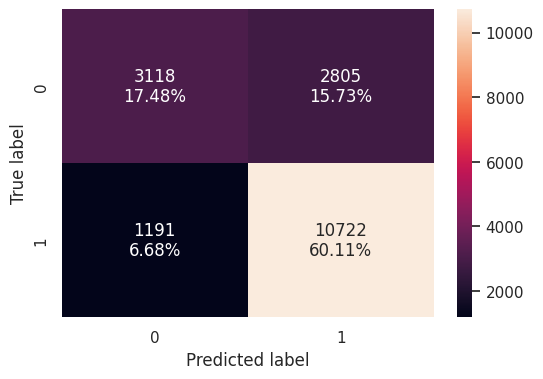

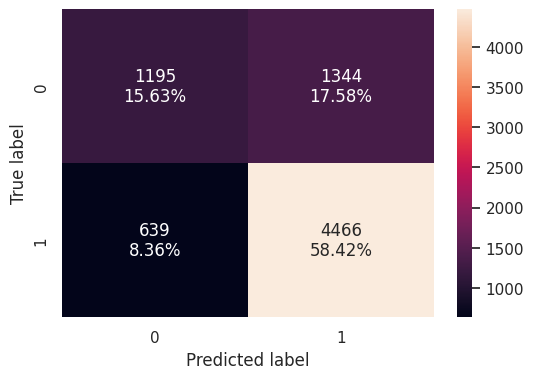

In [95]:
#C86
#create a confusion matrix of the classifier's performance on the testing data

confusion_matrix_sklearn(rf_estimator, x_train,y_train)
confusion_matrix_sklearn(rf_estimator, x_test,y_test)

In [96]:
#C87
rf_estimator_model_train_perf=model_performance_classification_sklearn(rf_estimator, x_train,y_train)
print("Training performance \n",rf_estimator_model_train_perf)

Training performance 
    Accuracy  Recall  Precision   F1
0      0.78    0.90       0.79 0.84


In [97]:
#C88
rf_estimator_model_test_perf=model_performance_classification_sklearn(rf_estimator, x_test, y_test)
print("Testing performance \n",rf_estimator_model_test_perf)

Testing performance 
    Accuracy  Recall  Precision   F1
0      0.74    0.87       0.77 0.82


#### tuned Random Forest
* The Random Forest after tuning performs equally well on the training and testing datasets, indicating that the model is not overfit.
* Additionally, this model performs as well as two out of the three boosting models and the tuned Decision Tree on the test data.
* Both of these indicate this tuned model is a significant improvements over the base model.

###Tuning the AdaBoost Classiefier
####Hyperparameters include:
   - base_estimator: The base estimator from which the boosted ensemble is built. By default the base estimator is a decision tree with max_depth=1
   - n_estimators: The maximum number of estimators at which boosting is terminated. Default value is 50.
   - learning_rate: Learning rate shrinks the contribution of each classifier by learning_rate. There is a trade-off between learning_rate and n_estimators.

In [123]:
#C89
# Choose the type of classifier.
abc_tuned = AdaBoostClassifier(random_state=1)

# Grid of parameters to choose from
## add from article
parameters = {
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=1, class_weight="balanced"),
        DecisionTreeClassifier(max_depth=2, random_state=1, class_weight="balanced"),
        DecisionTreeClassifier(max_depth=3, random_state=1, class_weight="balanced"),
    ],
    "n_estimators": np.arange(10, 110, 10),
    "learning_rate": np.arange(0.1, 1.1, 0.1),
}

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the randomized search
rand_abc = RandomizedSearchCV(abc_tuned, parameters, scoring=acc_scorer,cv=5, n_jobs=-1, random_state=1)
rand_abc = rand_abc.fit(x_train, y_train)

# Set the clf to the best combination of parameters
abc_tuned = rand_abc.best_estimator_

# Fit the best algorithm to the data.
print(abc_tuned.fit(x_train, y_train))

AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                    max_depth=1,
                                                    random_state=1),
                   learning_rate=np.float64(0.8), n_estimators=np.int64(40),
                   random_state=1)


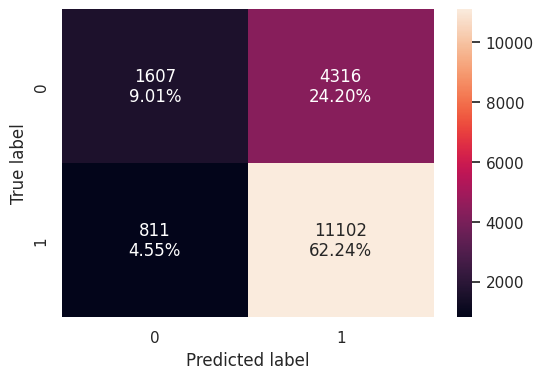

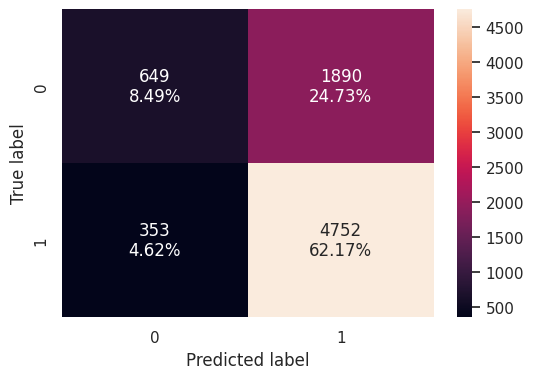

In [99]:
#C90
#create a confusion matrix of the classifier's performance on the testing data

confusion_matrix_sklearn(abc_tuned, x_train,y_train)
confusion_matrix_sklearn(abc_tuned, x_test,y_test)

In [100]:
#C91
abc_tuned_model_train_perf=model_performance_classification_sklearn(abc_tuned, x_train,y_train)
print("Training performance \n",abc_tuned_model_train_perf)

Training performance 
    Accuracy  Recall  Precision   F1
0      0.71    0.93       0.72 0.81


In [101]:
#C92
abc_tuned_model_test_perf=model_performance_classification_sklearn(abc_tuned, x_test, y_test)
print("Testing performance \n",abc_tuned_model_test_perf)

Testing performance 
    Accuracy  Recall  Precision   F1
0      0.71    0.93       0.72 0.81


####tuned AdaBoost

* Train F1 is 0.81. Test F1 is 0.81. Not overfitting.
* Test accuracy 0.71, recall 0.93, precision 0.72.
* Worse than the base Adaptive Boosting (AdaBoost) model, which was test F1 0.82 and accuracy 0.74.
* Quote the base AdaBoost model, not this tune.

###Tuning the GradientBoost Classiefier
####Most of the hyperparameters available match those of a random forest classifier.
  - init: An estimator object that is used to compute the initial predictions. If ‘zero’, the initial raw predictions are set to zero. By default, a DummyEstimator predicting the classes priors is used.
  - There is no class_weights parameter in gradient boosting.

In [102]:
# C92
gb_tuned = GradientBoostingClassifier(random_state=1)

parameters = {"n_estimators": [150, 200, 250, 300],
              "subsample": [0.8, 0.9, 1],
              "max_features": [0.7, 0.8, 0.9, 1],
              "learning_rate": np.arange(0.1, 0.4, 0.1)}

scorer = metrics.make_scorer(metrics.f1_score)

rand_gb = RandomizedSearchCV(gb_tuned, parameters, scoring=scorer, cv=5, n_jobs=-1, random_state=1)
rand_gb.fit(x_train, y_train)

print(rand_gb.best_params_)
print(rand_gb.best_score_)

gb_tuned = rand_gb.best_estimator_

{'subsample': 1, 'n_estimators': 300, 'max_features': 0.7, 'learning_rate': np.float64(0.1)}
0.8215271465160203


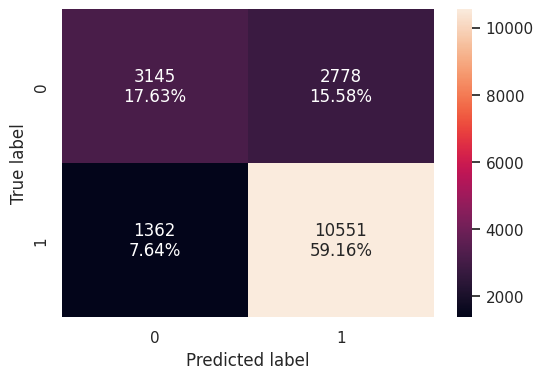

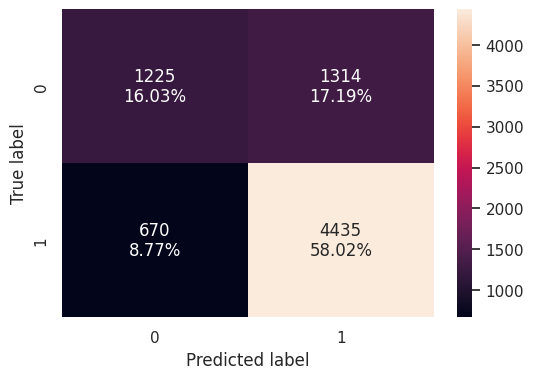

In [103]:
#C93
# Fit the best algorithm to the data.
confusion_matrix_sklearn(gb_tuned, x_train,y_train)
confusion_matrix_sklearn(gb_tuned, x_test,y_test)

In [104]:
#C95
gb_tuned_model_train_perf=model_performance_classification_sklearn(rf_estimator, x_train,y_train)
print("Training performance \n",gb_tuned_model_train_perf)

Training performance 
    Accuracy  Recall  Precision   F1
0      0.78    0.90       0.79 0.84


In [105]:
#C96
gb_tuned_model_test_perf=model_performance_classification_sklearn(rf_estimator, x_test, y_test)
print("Testing performance \n",gb_tuned_model_test_perf)

Testing performance 
    Accuracy  Recall  Precision   F1
0      0.74    0.87       0.77 0.82


####tuned Gradient Boost Classifier

The tuned Gradient Boosting model shows a small train–test gap (F1 0.84 → 0.82) and is not overfit. On the holdout it matches the base Gradient Boosting F1 of 0.82, so the search did not improve the model. Quote the base Gradient Boosting result for this family.

###Tuning the XGB classifier
Important parameters include:
- scale_pos_weight:Control the balance of positive and negative weights, useful for unbalanced classes. It has range from 0 to $\infty$.
- subsample: Corresponds to the fraction of observations (the rows) to subsample at each step. By default it is set to 1 meaning that we use all rows.
- colsample_bytree: Corresponds to the fraction of features (the columns) to use.
- colsample_bylevel: The subsample ratio of columns for each level. Columns are subsampled from the set of columns chosen for the current tree.
- colsample_bynode: The subsample ratio of columns for each node (split). Columns are subsampled from the set of columns chosen for the current level.
- max_depth: is the maximum number of nodes allowed from the root to the farthest leaf of a tree.
- learning_rate/eta: Makes the model more robust by shrinking the weights on each step.
- gamma: A node is split only when the resulting split gives a positive reduction in the loss function. Gamma specifies the minimum loss reduction required to make a split.

In [106]:
#C97
#  Choose the type of classifier.

xgb_tuned = XGBClassifier(random_state=1, eval_metric='logloss')

# Grid of parameters to choose from
parameters = {"n_estimators": np.arange(10,100,20),
              "scale_pos_weight":[0,1,2,5],
              "subsample":[0.5,0.7,0.9,1],
              "learning_rate":[0.01,0.1,0.2,0.05],
              "gamma":[0,1,3],
              "colsample_bytree":[0.5,0.7,0.9,1],
              "colsample_bylevel":[0.5,0.7,0.9,1]}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.f1_score)

# Run the randomized search
rand_xgb = RandomizedSearchCV(xgb_tuned, parameters, scoring=scorer,cv=5, n_jobs=-1, random_state=1)
rand_xgb.fit(x_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = rand_xgb.best_estimator_


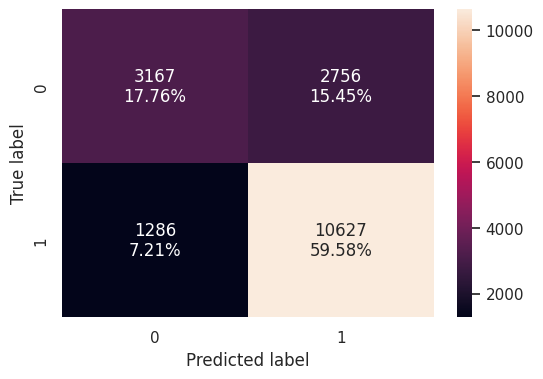

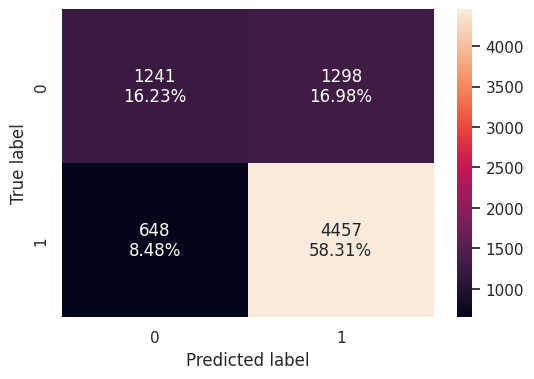

In [107]:
#C98
confusion_matrix_sklearn(xgb_tuned, x_train,y_train)
confusion_matrix_sklearn(xgb_tuned, x_test,y_test)


In [108]:
#C99
xgb_tuned_model_train_perf=model_performance_classification_sklearn(xgb_tuned, x_train,y_train)
print("Training performance \n",xgb_tuned_model_train_perf)

Training performance 
    Accuracy  Recall  Precision   F1
0      0.77    0.89       0.79 0.84


In [109]:
#C100
xgb_tuned_model_test_perf=model_performance_classification_sklearn(xgb_tuned, x_test, y_test)
print("Testing performance \n",xgb_tuned_model_test_perf)

Testing performance 
    Accuracy  Recall  Precision   F1
0      0.75    0.87       0.77 0.82


####tuned Extreme Gradient Boosting (XGBoost)
The randomized search produced a model with a small train–test gap (F1 0.84 → 0.82) and no sign of overfit. On the holdout it reaches F1 0.82, one point above the base Extreme Gradient Boosting (XGBoost) model (0.81) and level with the best results so far (tuned Random Forest 0.82 and base Gradient Boosting 0.82).



###Stacking Classifier
Stacking
Stacking (stacked generalization) is an ensemble method that combines the predictions of several base models by training a second-level model (the meta-learner) on those predictions.

How it works

The base models (here: tuned Random Forest, base Gradient Boosting, tuned Extreme Gradient Boosting (XGBoost)) each make their own predictions on the training data.
Those predictions become the input features for the meta-learner (here: Logistic Regression).
The meta-learner learns how to weight or correct the base models’ outputs to produce a final prediction.

Goal

Capture the strengths of different algorithms while reducing the weaknesses of any single one.
Often improves accuracy or F1 when the base models make different kinds of errors.
In this notebook the stack ties the best single models (F1 ≈ 0.82) but does not clearly outperform them.

In [124]:
#C101
from sklearn.linear_model import LogisticRegression
# Stacking classifier
# Base estimators: the three strongest models so far
# Meta-learner: logistic regression (simple, no extra tuning)

estimators = [
    ("rf", rf_estimator),
    ("gb", gbc),
    ("xgb", xgb_tuned),
]

stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=1, max_iter=1000),
    cv=5,
    n_jobs=-1,
)

print(stacking.fit(x_train, y_train))

StackingClassifier(cv=5,
                   estimators=[('rf',
                                RandomForestClassifier(max_features='log2',
                                                       max_samples=np.float64(0.6000000000000001),
                                                       min_samples_leaf=np.int64(7),
                                                       min_samples_split=7,
                                                       n_estimators=np.int64(20),
                                                       random_state=1)),
                               ('gb',
                                GradientBoostingClassifier(random_state=1)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylev...
                                              learning_rate=0.1, max_bin=None,
         

In [111]:
#C102
# Stacking performance on the test set

y_pred = stacking.predict(x_test)

print("Stacking")
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("Precision:", metrics.precision_score(y_test, y_pred))
print("Recall:", metrics.recall_score(y_test, y_pred))
print("F1:", metrics.f1_score(y_test, y_pred))

Stacking
Accuracy: 0.7450287807430664
Precision: 0.7737682165163081
Recall: 0.8736532810969637
F1: 0.820682675499126


#### Stacking
Stacking ties the strongest single models (base AdaBoost / base Gradient Boosting / tuned Random Forest, all at 0.82). It does not clearly beat them.

###Tuned Model COmparison

In [112]:
#C103
# create a dataframe comparing the performance of the tuned models on the training data

tuned_models_train_comp_df = pd.concat(
    [dtree_estimator_model_train_perf.T,
     bagging_estimator_model_train_perf.T,
     rf_estimator_model_train_perf.T,
     abc_tuned_model_train_perf.T,
     gb_tuned_model_train_perf.T,
     xgb_tuned_model_train_perf.T],
    axis=1,
)
tuned_models_train_comp_df.columns = [
    "Tuned Decision Tree",
    "Tuned Bagging Classifier",
    "Tuned Random Forest",
    "Tuned AdaBoost Classifier",
    "Tuned Gradient Boosting Classifier",
    "Tuned XGBoost Classifier"]
print("Training performance comparison of tuned models:")
print(tuned_models_train_comp_df)

Training performance comparison of tuned models:
           Tuned Decision Tree  Tuned Bagging Classifier  Tuned Random Forest  \
Accuracy                  0.73                      1.00                 0.78   
Recall                    0.91                      1.00                 0.90   
Precision                 0.74                      1.00                 0.79   
F1                        0.82                      1.00                 0.84   

           Tuned AdaBoost Classifier  Tuned Gradient Boosting Classifier  \
Accuracy                        0.71                                0.78   
Recall                          0.93                                0.90   
Precision                       0.72                                0.79   
F1                              0.81                                0.84   

           Tuned XGBoost Classifier  
Accuracy                       0.77  
Recall                         0.89  
Precision                      0.79  
F1          

In [113]:
#C104
# create a dataframe comparing the performance of the tuned models on the testing data

tuned_models_test_comp_df = pd.concat(
    [dtree_estimator_model_test_perf.T,
     bagging_estimator_model_test_perf.T,
     rf_estimator_model_test_perf.T,
     abc_tuned_model_test_perf.T,
     gb_tuned_model_test_perf.T,
     xgb_tuned_model_test_perf.T],
    axis=1,
)
tuned_models_test_comp_df.columns = [
    "Tuned Decision Tree",
    "Tuned Bagging Classifier",
    "Tuned Random Forest",
    "Tuned AdaBoost Classifier",
    "Tuned Gradient Boosting Classifier",
    "Tuned XGBoost Classifier"]
print("Testing performance comparison of tuned models:")
print(tuned_models_test_comp_df)

Testing performance comparison of tuned models:
           Tuned Decision Tree  Tuned Bagging Classifier  Tuned Random Forest  \
Accuracy                  0.72                      0.73                 0.74   
Recall                    0.91                      0.87                 0.87   
Precision                 0.74                      0.76                 0.77   
F1                        0.81                      0.81                 0.82   

           Tuned AdaBoost Classifier  Tuned Gradient Boosting Classifier  \
Accuracy                        0.71                                0.74   
Recall                          0.93                                0.87   
Precision                       0.72                                0.77   
F1                              0.81                                0.82   

           Tuned XGBoost Classifier  
Accuracy                       0.75  
Recall                         0.87  
Precision                      0.77  
F1           

##Model Performance Comparison

In [114]:
#C105
#  create a dataframe comparing the performance all models on the training data
# sort on F1
all_models_train_comp = pd.concat([models_train_comp_df,tuned_models_train_comp_df],axis=1)
print(all_models_train_comp.T.sort_values('F1',ascending=False))

                                    Accuracy  Recall  Precision   F1
Decision Tree                           1.00    1.00       1.00 1.00
Random Forest                           1.00    1.00       1.00 1.00
Tuned Bagging Classifier                1.00    1.00       1.00 1.00
Bagging Classifier                      0.99    0.99       0.99 0.99
XGBoost Classifier                      0.84    0.93       0.85 0.89
Tuned Gradient Boosting Classifier      0.78    0.90       0.79 0.84
Tuned Random Forest                     0.78    0.90       0.79 0.84
Tuned XGBoost Classifier                0.77    0.89       0.79 0.84
Gradient Boosting Classifier            0.76    0.88       0.78 0.83
AdaBoost Classifier                     0.74    0.89       0.76 0.82
Tuned Decision Tree                     0.73    0.91       0.74 0.82
Tuned AdaBoost Classifier               0.71    0.93       0.72 0.81


In [115]:
#C106
#  create a dataframe comparing the performance all models on the training data
# sort on Precision
all_models_test_comp = pd.concat([models_test_comp_df,tuned_models_test_comp_df],axis=1)
print(all_models_test_comp.T.sort_values('Precision',ascending=False))

                                    Accuracy  Recall  Precision   F1
Tuned XGBoost Classifier                0.75    0.87       0.77 0.82
Gradient Boosting Classifier            0.74    0.88       0.77 0.82
Bagging Classifier                      0.69    0.76       0.77 0.77
XGBoost Classifier                      0.73    0.85       0.77 0.81
Random Forest                           0.72    0.83       0.77 0.80
Tuned Random Forest                     0.74    0.87       0.77 0.82
Tuned Gradient Boosting Classifier      0.74    0.87       0.77 0.82
AdaBoost Classifier                     0.74    0.88       0.76 0.82
Tuned Bagging Classifier                0.73    0.87       0.76 0.81
Decision Tree                           0.65    0.75       0.74 0.74
Tuned Decision Tree                     0.72    0.91       0.74 0.81
Tuned AdaBoost Classifier               0.71    0.93       0.72 0.81


In [116]:
#C107
# create a dataframe comparing the performance all models on the training data
# sort on Recall
all_models_test_comp = pd.concat([models_test_comp_df,tuned_models_test_comp_df],axis=1)
print(all_models_test_comp.T.sort_values('Recall',ascending=False))

                                    Accuracy  Recall  Precision   F1
Tuned AdaBoost Classifier               0.71    0.93       0.72 0.81
Tuned Decision Tree                     0.72    0.91       0.74 0.81
AdaBoost Classifier                     0.74    0.88       0.76 0.82
Gradient Boosting Classifier            0.74    0.88       0.77 0.82
Tuned Gradient Boosting Classifier      0.74    0.87       0.77 0.82
Tuned Random Forest                     0.74    0.87       0.77 0.82
Tuned XGBoost Classifier                0.75    0.87       0.77 0.82
Tuned Bagging Classifier                0.73    0.87       0.76 0.81
XGBoost Classifier                      0.73    0.85       0.77 0.81
Random Forest                           0.72    0.83       0.77 0.80
Bagging Classifier                      0.69    0.76       0.77 0.77
Decision Tree                           0.65    0.75       0.74 0.74


In [117]:
#C108
#  create a dataframe comparing the performance all models on the training data
# sort on Accuracy
all_models_test_comp = pd.concat([models_test_comp_df,tuned_models_test_comp_df],axis=1)
print(all_models_test_comp.T.sort_values('Accuracy',ascending=False))

                                    Accuracy  Recall  Precision   F1
Tuned XGBoost Classifier                0.75    0.87       0.77 0.82
Gradient Boosting Classifier            0.74    0.88       0.77 0.82
Tuned Gradient Boosting Classifier      0.74    0.87       0.77 0.82
Tuned Random Forest                     0.74    0.87       0.77 0.82
AdaBoost Classifier                     0.74    0.88       0.76 0.82
XGBoost Classifier                      0.73    0.85       0.77 0.81
Tuned Bagging Classifier                0.73    0.87       0.76 0.81
Tuned Decision Tree                     0.72    0.91       0.74 0.81
Random Forest                           0.72    0.83       0.77 0.80
Tuned AdaBoost Classifier               0.71    0.93       0.72 0.81
Bagging Classifier                      0.69    0.76       0.77 0.77
Decision Tree                           0.65    0.75       0.74 0.74


####comparing model performance

Test-set ranking (F1):
- Top cluster at F1 0.82: Tuned XGBoost, Gradient Boosting (base), Tuned Random Forest, Tuned Gradient Boosting, AdaBoost (base).
- Close behind at F1 0.81: Tuned Bagging, Tuned Decision Tree, Tuned AdaBoost, XGBoost (base).
- Lower: Random Forest (base) 0.80, Bagging (base) 0.77, Decision Tree (base) 0.74.

Recall ranking (if missing a certified case is costly):
- Tuned AdaBoost 0.93, Tuned Decision Tree 0.91, then the F1=0.82 cluster at 0.87–0.88.

Accuracy ranking:
- Tuned XGBoost 0.75, then several models at 0.74.

Overfit note:
- Decision Tree, Random Forest, and Tuned Bagging reach perfect or near-perfect train scores (1.00 / 0.99) but drop on test. Tuning helped the tree and forest; it did not improve AdaBoost or Gradient Boosting.

No single model dominates every metric. The choice depends on whether the Office of Foreign Labor Certification prioritizes Recall or balanced F1/Accuracy.


###Feature importance of Gradient Boosting Classifier
The importance of a feature is computed as the (normalized) total reduction of the criterion brought by that feature.

In [118]:
#C109
print(pd.DataFrame(gbc.feature_importances_, columns = ["Imp"],
                   index = x_train.columns).sort_values(by = 'Imp', ascending = False).head(25))

                                   Imp
education_of_employee_High School 0.29
has_job_experience_Y              0.16
prevailing_wage                   0.14
education_of_employee_Master's    0.09
education_of_employee_Doctorate   0.08
continent_Europe                  0.06
unit_of_wage_Year                 0.04
region_of_employment_Midwest      0.03
region_of_employment_South        0.02
no_of_employees                   0.01
continent_North America           0.01
yr_of_estab                       0.01
region_of_employment_West         0.01
continent_Asia                    0.01
full_time_position_Y              0.01
region_of_employment_Northeast    0.01
continent_South America           0.01
requires_job_training_Y           0.00
continent_Oceania                 0.00
unit_of_wage_Month                0.00
unit_of_wage_Week                 0.00


#### feature importance
We can see that a high school education is the most important feature, followed by job experience, prevailing wage, and higher education levels (Master’s and Doctorate).

##Visualizations of the Decision Tree

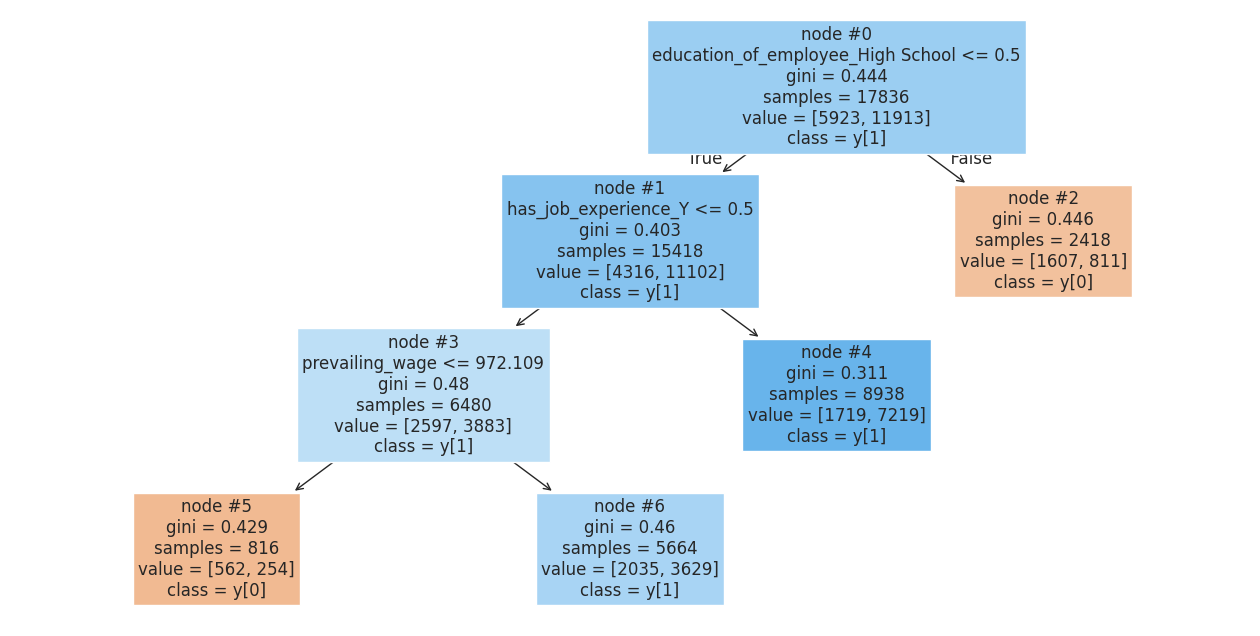

In [119]:
#C110
# create visualization of tuned decision-tree model
feature_names = list(X.columns)
plt.figure(figsize=(16,8))
tree.plot_tree(dtree_estimator,feature_names=feature_names,filled=True,fontsize=12,node_ids=True,class_names=True)
plt.show()

### Tuned Decision Tree

The Gini Index (impurity) measures how mixed the classes are at a node. Lower Gini means the node is purer.

The root split is education_of_employee_High School, followed by has_job_experience_Y and prevailing_wage. These match the top features from the Gradient Boosting importance ranking.

Test performance of this tree is Recall 0.91 and F1 0.81 (see comparison table).

## Actionable Insights and Recommendations

The key features for ranking candidates are:
A. education_of_employee — High School is the strongest negative signal; Master’s and Doctorate are positive.
B. has_job_experience — prior experience increases the chance of certification.
C. prevailing_wage — higher wage is associated with higher certification probability. unit_of_wage_Year has a smaller positive effect; Month and Week show negligible importance.

Queue ordering that follows the model:
1. Education: Doctorate, then Master’s, then Bachelor’s, then High School.
2. Within each education level, prefer candidates with job experience.
3. Within those groups, prefer higher prevailing wage (and Year wage unit over Hour).

Process recommendations (not model outputs):
1. Keep an audit trail of certified and denied candidates so model accuracy can be tracked over time.
2. Periodically review a random sample of lower-ranked cases (for example, every 10th selection from the bottom quartile) to check for systematic misses.
3. Each entry is a person. The model is a ranking aid, not a final decision.

## Final Insights and Recommendations

The strongest single models (base Gradient Boosting, base AdaBoost, and tuned Random Forest) all reach a test F1 of 0.82. Stacking ties these models and does not clearly improve on them. For deployment, a single Gradient Boosting model is sufficient.

**Key drivers (from Gradient Boosting feature importance and the tuned Decision Tree)**

- **education_of_employee** is the dominant signal. High School education is the strongest negative predictor (importance 0.29). Master’s and Doctorate levels are positive relative to the High School baseline.
- **has_job_experience** is the second-strongest feature (importance 0.16). Prior experience increases the probability of certification.
- **prevailing_wage** is the strongest continuous predictor (importance 0.14). Higher wage is associated with higher certification probability. The unit_of_wage_Year dummy has a smaller positive effect; Month and Week show negligible importance.

**Queue ordering that follows the model**

1. Education: Doctorate, then Master’s, then Bachelor’s, then High School.
2. Within each education level, prefer candidates with job experience.
3. Within those groups, prefer higher prevailing wage (Year wage unit over Hour).

**Process recommendations**

1. Maintain an audit trail of certified and denied candidates so model accuracy can be monitored over time.
2. Periodically review a random sample of lower-ranked cases (for example, every 10th selection from the bottom quartile) to check for systematic misses.
3. Each record is a person. The model is a ranking aid, not a final decision.

In [120]:
#C111
#Most likely canidates
proba = gbc.predict_proba(x_test)[:, 1]
top5 = (
    x_test.assign(cert_prob=proba)
    .sort_values("cert_prob", ascending=False)
    .head(5)
)
print(top5[["education_of_employee_High School",
            "education_of_employee_Master's",
            "education_of_employee_Doctorate",
            "has_job_experience_Y",
            "prevailing_wage",
            "cert_prob"]].to_string())

       education_of_employee_High School  education_of_employee_Master's  education_of_employee_Doctorate  has_job_experience_Y  prevailing_wage  cert_prob
24481                              False                            True                            False                  True        235875.97       0.97
7280                               False                            True                            False                  True        180066.44       0.96
18108                              False                           False                             True                  True         80500.16       0.96
18507                              False                            True                            False                  True         88465.75       0.96
25102                              False                            True                            False                  True         64493.93       0.96


In [121]:
#C112
#Least likely canidates
proba = gbc.predict_proba(x_test)[:, 1]
bottom5 = (
    x_test.assign(cert_prob=proba)
    .sort_values("cert_prob", ascending=True)
    .head(5)
)
print(bottom5[["education_of_employee_High School",
               "education_of_employee_Master's",
               "education_of_employee_Doctorate",
               "has_job_experience_Y",
               "prevailing_wage",
               "cert_prob"]].to_string())

       education_of_employee_High School  education_of_employee_Master's  education_of_employee_Doctorate  has_job_experience_Y  prevailing_wage  cert_prob
6387                                True                           False                            False                 False           769.49       0.10
25367                               True                           False                            False                 False        125704.68       0.11
3781                                True                           False                            False                 False           762.01       0.12
12102                               True                           False                            False                 False        127303.96       0.12
17233                              False                           False                            False                 False           953.48       0.12
